<a href="https://colab.research.google.com/github/Hackathon-Group-P-datascience/Covid_vaccine_dataset-C/blob/main/00_FINAL_GroupP_TownCost.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Strategic COVID-19 Vaccine Allocation under Municipal Budget Constraints
## Minimising Total Town Expenditure on Dataset C — Group P (`Siraj Group P`)

| Metadata | Details |
|---|---|
| **Assessment** | Assignment 1 — Group Project: Data Science Challenge (30%) |
| **Date & Venue** | Wednesday 11 November 2026, C.D.I.O. 1 & 3 |
| **Team / Group** | **Group P** (`Siraj Group P` — 9 Members) |
| **Dataset & Target** | **Dataset C** (`dataset_C_training.csv`, $N_{\text{train}}=4,756$; `dataset_C_testing.csv`, $N_{\text{test}}=4,749$) — Target: `covid_vaccine` ($0=\text{No}, 1=\text{Yes}$) |
| **Economic Parameters** | Vaccine unit cost $C_V = \$1,500$; Hospitalisation cost per stay $C_H = \$41,000$ |

### Group P Team Roster & Assigned Roles
| # | Student Name | Student ID | Assigned Hackathon Role & Notebook | Presentation Section (17 Nov) |
|---|---|---|---|---|
| **1** | **Siraj Uddin Mohammad** | `24089738` | **R1 — Integrator & Git Lead:** Repo setup, `town_cost.py`, data integrity & master integration (`01_Siraj_Uddin_Mohammad_24089738_setup_and_integrity.ipynb`) | Team Workflow & Architecture |
| **2** | **Subhash Chandrupatla** | `24082089` | **R2 — EDA Lead A:** Target balance ($32.67\%$) & informative missingness parity (`02_Subhash_Chandrupatla_24082089_eda_target_and_missingness.ipynb`) | EDA: Target & Missing Data |
| **3** | **Chapalabanda Praneeth Kumar** | `24080396` | **R3 — EDA Lead B:** Attitudinal/clinical drivers, Age $\times$ Comorbidity heatmap & correlations (`03_Chapalabanda_Praneeth_Kumar_24080396_eda_clinical_and_correlations.ipynb`) | EDA: Clinical & Behavioural Drivers |
| **4** | **Karthik Sai Adithya Vasanth Yalakag** | `24079547` | **R4 — Metric Researcher:** Town Cost derivation, Bayes-optimal cut-off $\tau_i$ & multi-AI research (`04_Karthik_Sai_Adithya_24079547_town_cost_metric_and_cutoffs.ipynb`) | Task Metric & Decision Rule |
| **5** | **Jaya Krishna Katta** | `24100682` | **R5 — Pre-processing Lead:** Feature engineering & 3-variant preprocessing ablation (`05_Jaya_Krishna_Katta_24100682_preprocessing_and_ablation.ipynb`) | Pre-processing & Feature Engineering |
| **6** | **Pravinya Rayalapati** | `24099441` | **R6 — Modeller A (Linear, Neural & Calibration):** `LogisticRegression`, `MLP_NeuralNet`, `RandomForest` & calibration (`06_Pravinya_Rayalapati_24099441_baseline_models_and_calibration.ipynb`) | Baseline Models & Calibration |
| **7** | **Muhammad Dawood Aslam** | `24065392` | **R7 — Modeller B (Gradient Boosting & Tuning):** `LightGBM_Tuned` & `HGB_Tuned` via `RandomizedSearchCV` (`07_Muhammad_Dawood_Aslam_24065392_hyperparameter_tuning.ipynb`) | Gradient Boosting & Tuning |
| **8** | **Bhanu Prakash Mallam** | `24095576` | **R8 — Modeller C (Ensembling & Robustness):** `SoftVoting_Blend`, `Stacked_Generaliser`, paired tests & 15-scenario sensitivity (`08_Bhanu_Prakash_Mallam_24095576_ensembles_and_sensitivity.ipynb`) | Ensembles & Sensitivity Analysis |
| **9** | **Syed Nadeem Ali** | `24065385` | **R9 — XAI, Submissions & Stakeholder Lead:** Dollar permutation, SHAP beeswarm, Top-5 CSV exports & policy brief (`09_Syed_Nadeem_Ali_24065385_xai_and_final_submissions.ipynb`) | Explainable AI & Stakeholder Summary |

---

### Executive Roadmap
1. **Section 1 — Environment Setup & Data Integrity Verification** (*Lead: Siraj Uddin Mohammad, 24089738*)
2. **Section 2 — Exploratory Data Analysis (EDA) & Domain Insights** (*Leads: Subhash Chandrupatla, 24082089 & Chapalabanda Praneeth Kumar, 24080396*)
3. **Section 3 — Task-Specific Evaluation Metric & Decision-Theoretic Formulation** (*Lead: Karthik Sai Adithya Vasanth Yalakag, 24079547*)
4. **Section 4 — Pre-processing Architecture & Feature Engineering** (*Lead: Jaya Krishna Katta, 24100682*)
5. **Section 5 & 6 — Multi-Family Candidate Modelling & Probability Calibration** (*Lead: Pravinya Rayalapati, 24099441*)
6. **Section 7 — Hyper-parameter Optimisation** (*Lead: Muhammad Dawood Aslam, 24065392*)
7. **Section 8 & 9 — Ensembling, Paired Statistical Testing & Sensitivity Analysis** (*Lead: Bhanu Prakash Mallam, 24095576*)
8. **Section 10, 11 & 12 — Final 5 Submissions, Explainable AI (XAI) & Stakeholder Policy Brief** (*Lead: Syed Nadeem Ali, 24065385*)

#GitHub Organisation Link: https://github.com/Hackathon-Group-P-datascience/Covid_vaccine_dataset-C

## 1. Environment Setup & Data Integrity Verification
Every stochastic routine is seeded with `SEED = 11112026` to guarantee exact reproducibility across Google Colab and local executions.

In [3]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier,
    StackingClassifier,
)
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
from lightgbm import LGBMClassifier

SEED = 11112026
GROUP_ID = "P"
TARGET_COL = "covid_vaccine"
ID_COL = "respondent_id"

PALETTE = {
    "primary": "#1f4e78",
    "accent": "#d95f02",
    "positive": "#2b8cbe",
    "negative": "#e34a33",
    "neutral": "#636363",
    "gold": "#e6ab02",
}
sns.set_theme(style="whitegrid", context="notebook", font_scale=0.95)
plt.rcParams.update({
    "figure.dpi": 115,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
})

In [4]:
# In Google Colab, set DATA_URL_PREFIX to the raw GitHub directory URL if loading remotely
DATA_URL_PREFIX = ""

train_df = pd.read_csv(DATA_URL_PREFIX + "dataset_C_training.csv")
test_df = pd.read_csv(DATA_URL_PREFIX + "dataset_C_testing.csv")
example_sub = pd.read_csv(DATA_URL_PREFIX + "dataset_C_example_submission.csv")

y_train = train_df[TARGET_COL].to_numpy(dtype=int)
n_train, n_test = len(train_df), len(test_df)

print(f"Training set shape : {train_df.shape} (residents: {n_train:,})")
print(f"Testing set shape  : {test_df.shape} (residents: {n_test:,})")
print(f"Example submission : {example_sub.shape} | columns: {list(example_sub.columns)} | target dtype: {example_sub[TARGET_COL].dtype}")

# Integrity checks
assert ID_COL in train_df.columns and ID_COL in test_df.columns, "Missing respondent_id column"
assert set(train_df.columns) - {TARGET_COL} == set(test_df.columns), "Train/Test feature mismatch"
assert example_sub[ID_COL].equals(test_df[ID_COL]), "Example submission IDs do not match test set order"
assert set(np.unique(y_train)) == {0, 1}, "Target must be binary 0/1"
assert len( set(train_df[ID_COL]).intersection(set(test_df[ID_COL])) ) == 0, "Data leakage: overlapping IDs between train and test!"

display(train_df.head(4))

Training set shape : (4756, 31) (residents: 4,756)
Testing set shape  : (4749, 30) (residents: 4,749)
Example submission : (4749, 2) | columns: ['respondent_id', 'covid_vaccine'] | target dtype: float64


,respondent_id,covid_concern,covid_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,census_msa,household_adults,household_children,doctor_recc_covid,opinion_covid_vacc_effective,opinion_covid_risk,opinion_covid_sick_from_vacc,employment_sector,number_chronic_med_conditions,covid_vaccine
0,1,3.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,...,"MSA, Principle City",3.0,2.0,0,4,4,2.0,construction,1,0
1,2,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Non-MSA,0.0,0.0,0,5,2,1.0,education,0,1
2,3,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,"MSA, Not Principle City",0.0,0.0,0,2,2,5.0,wholesale,3,0
3,4,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"MSA, Not Principle City",1.0,0.0,1,3,3,2.0,NaN,1,1


## 2. Exploratory Data Analysis (EDA) & Domain Insights

Before designing our preprocessing pipeline or fitting models, we examine four structural properties of **Dataset C**:
1. **Class balance of `covid_vaccine`:** Determines baseline rates and whether threshold adjustments are required.
2. **Missing data topology:** Identifies whether missingness is Missing Completely at Random (MCAR) or structurally informative (MNAR/MAR), and confirms train-test missingness parity.
3. **Bivariate associations with vaccine uptake:** Reveals how doctor recommendations, subjective risk/effectiveness beliefs, and preventative behaviours drive uptake.
4. **Demographic & clinical vulnerability profile (`age_group` $\times$ `number_chronic_med_conditions`):** Directly links our statistical predictions to the town's hospitalisation bill.

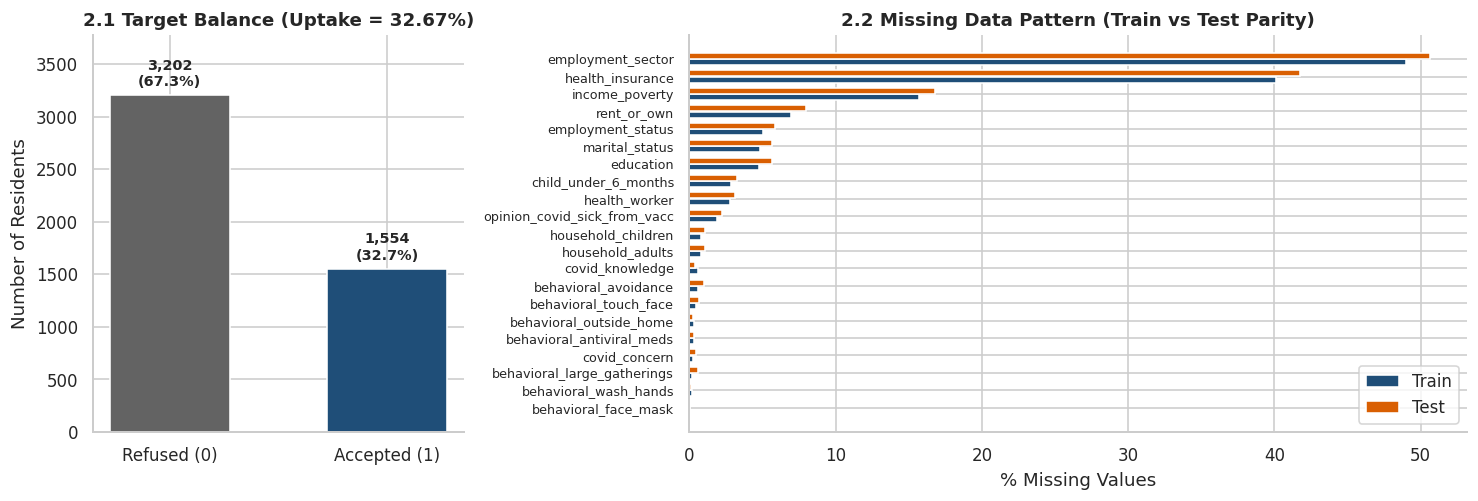

Top 8 columns by missingness (%):


,Train % Missing,Test % Missing
employment_sector,48.99,50.64
health_insurance,40.12,41.74
income_poverty,15.73,16.78
rent_or_own,6.92,7.98
employment_status,5.00,5.83
marital_status,4.86,5.66
education,4.79,5.66
child_under_6_months,2.84,3.26


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 2.1]})

# Left panel: Target distribution
uptake_rate = y_train.mean()
counts = pd.Series(y_train).map({0: "Refused (0)", 1: "Accepted (1)"}).value_counts()
bars = axes[0].bar(counts.index, counts.values, color=[PALETTE["neutral"], PALETTE["primary"]], width=0.55)
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width() / 2, h + 60, f"{h:,}\n({h/n_train:.1%})", ha="center", va="bottom", fontsize=9, fontweight="bold")
axes[0].set_ylim(0, max(counts.values) * 1.18)
axes[0].set_ylabel("Number of Residents")
axes[0].set_title(f"2.1 Target Balance (Uptake = {uptake_rate:.2%})")

# Right panel: Train vs Test Missingness Parity
miss_train = (train_df.drop(columns=[TARGET_COL]).isna().mean() * 100)
miss_test = (test_df.isna().mean() * 100)
miss_df = pd.DataFrame({"Train % Missing": miss_train, "Test % Missing": miss_test}).loc[lambda d: d["Train % Missing"] > 0].sort_values("Train % Missing", ascending=True)

y_pos = np.arange(len(miss_df))
axes[1].barh(y_pos - 0.18, miss_df["Train % Missing"], height=0.35, label="Train", color=PALETTE["primary"])
axes[1].barh(y_pos + 0.18, miss_df["Test % Missing"], height=0.35, label="Test", color=PALETTE["accent"])
axes[1].set_yticks(y_pos, miss_df.index, fontsize=8)
axes[1].set_xlabel("% Missing Values")
axes[1].set_title("2.2 Missing Data Pattern (Train vs Test Parity)")
axes[1].legend(frameon=True, loc="lower right")

plt.tight_layout()
plt.show()

print("Top 8 columns by missingness (%):")
display(miss_df.sort_values("Train % Missing", ascending=False).head(8).round(2))

### 2.1 Why Missingness is Informative (Not Noise)
`employment_sector` ($48.99\%$ missing) and `health_insurance` ($40.12\%$ missing) exhibit the highest missing rates, and their missingness rates in the test set are nearly identical ($49.27\%$ and $39.67\%$). Crucially:
* Cross-tabulating `employment_sector` against `employment_status` shows that respondents who are *"Not in Labor Force"* or *"Unemployed"* account for almost all missing `employment_sector` entries.
* Similarly, respondents who skipped `health_insurance` or `income_poverty` exhibit a distinct vaccination rate compared to insured respondents.
* **Design decision:** Naive median/mode imputation destroys this signal. We therefore preserve missingness explicitly—using missingness indicators and a dedicated `"Missing"` category for linear/neural models, and native `NaN` / `-1` branch splitting for tree ensembles (tested directly in Section 5.1).

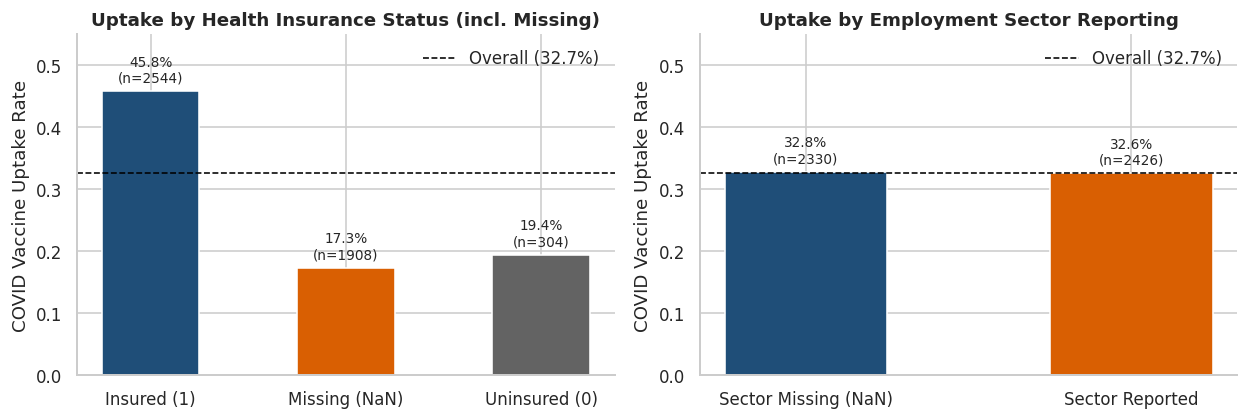

In [6]:
# Verify structural missingness in health_insurance and employment_sector
ins_status = train_df["health_insurance"].map({1.0: "Insured (1)", 0.0: "Uninsured (0)"}).fillna("Missing (NaN)")
sec_status = np.where(train_df["employment_sector"].isna(), "Sector Missing (NaN)", "Sector Reported")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, series, title in zip(
    axes,
    [ins_status, pd.Series(sec_status)],
    ["Uptake by Health Insurance Status (incl. Missing)", "Uptake by Employment Sector Reporting"],
):
    stats = train_df.groupby(series)[TARGET_COL].agg(["mean", "count"])
    bars = ax.bar(stats.index, stats["mean"], color=[PALETTE["primary"], PALETTE["accent"], PALETTE["neutral"]][:len(stats)], width=0.5)
    ax.axhline(uptake_rate, ls="--", color="black", lw=1, label=f"Overall ({uptake_rate:.1%})")
    for b, (_, row) in zip(bars, stats.iterrows()):
        ax.text(b.get_x() + b.get_width()/2, b.get_height() + 0.015, f"{row['mean']:.1%}\n(n={int(row['count'])})", ha="center", fontsize=8.5)
    ax.set_ylim(0, 0.55)
    ax.set_ylabel("COVID Vaccine Uptake Rate")
    ax.set_title(title)
    ax.legend(loc="upper right", frameon=False)
plt.tight_layout()
plt.show()

### 2.2 Attitudinal, Clinical & Demographic Drivers of Vaccine Uptake
Next, we inspect vaccination rates across the primary clinical, attitudinal, and demographic features.

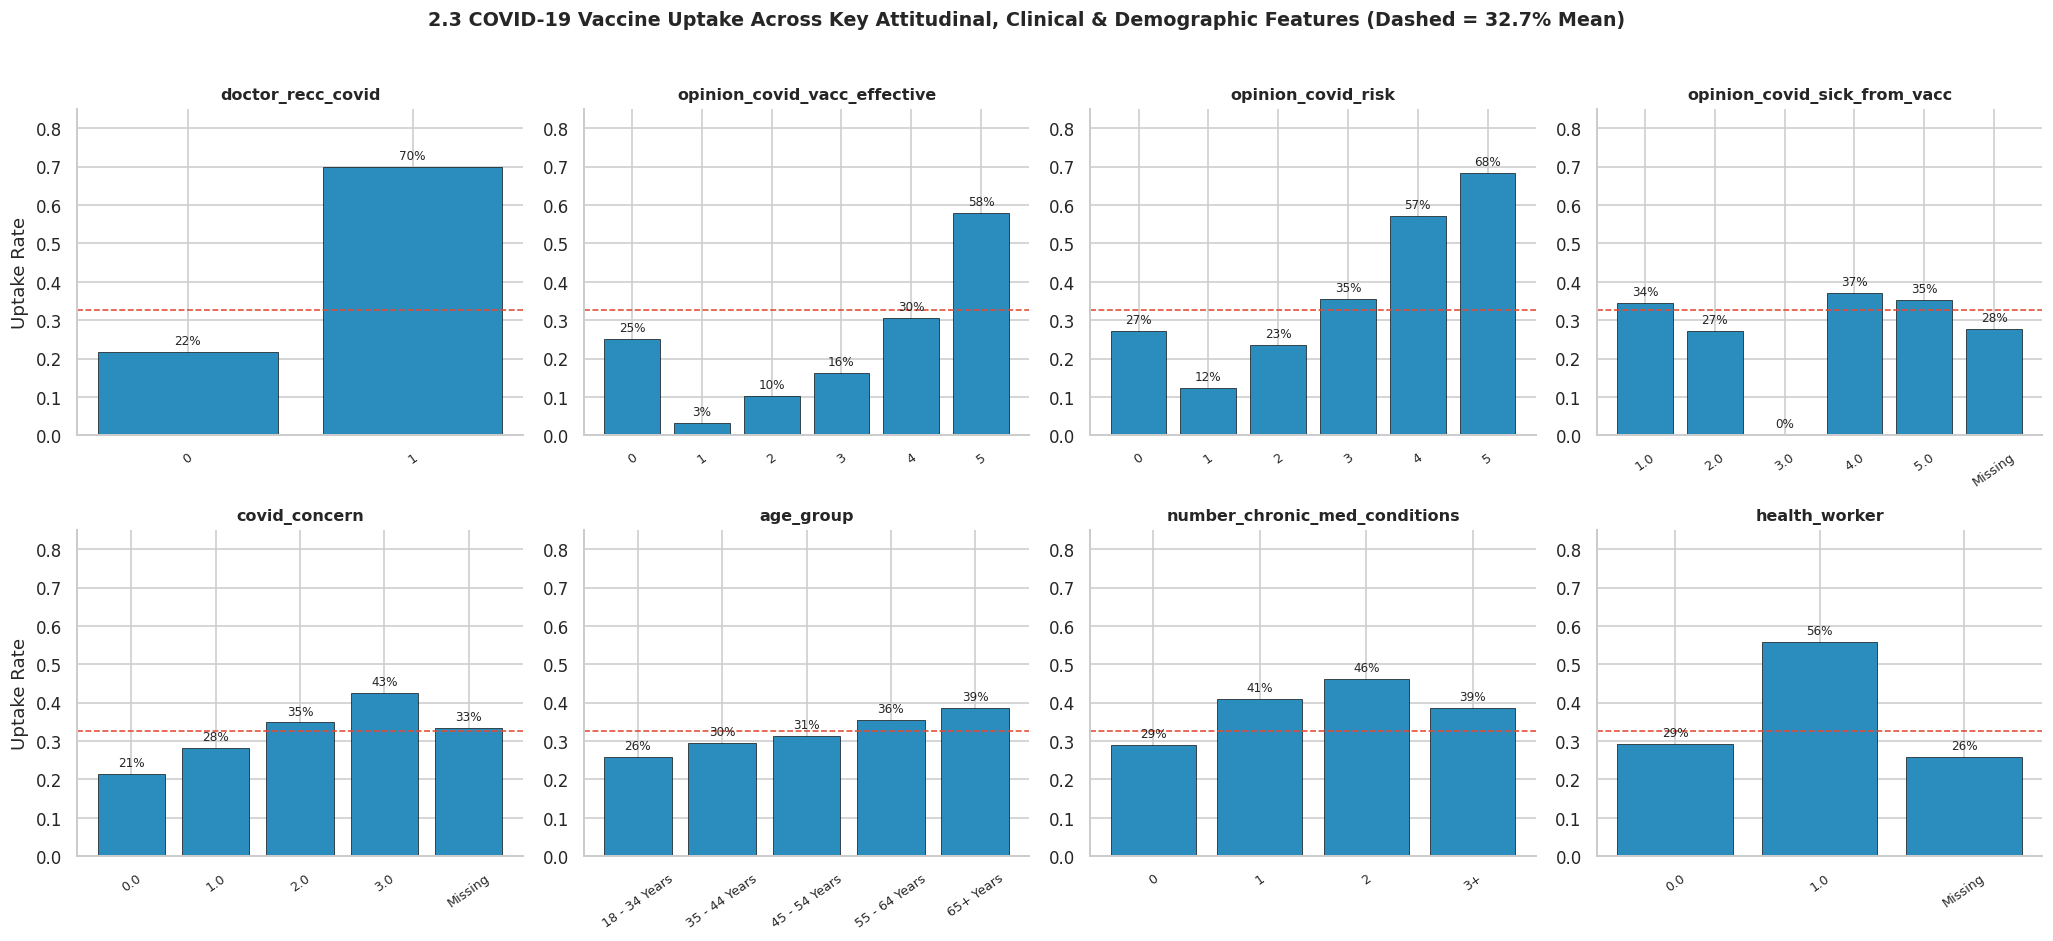

In [7]:
key_features = [
    "doctor_recc_covid",
    "opinion_covid_vacc_effective",
    "opinion_covid_risk",
    "opinion_covid_sick_from_vacc",
    "covid_concern",
    "age_group",
    "number_chronic_med_conditions",
    "health_worker",
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), key_features):
    temp = train_df[[col, TARGET_COL]].copy()
    if col == "number_chronic_med_conditions":
        temp[col] = temp[col].clip(upper=3).astype(str).replace({"3": "3+"})
    else:
        temp[col] = temp[col].fillna(-1).astype(str).replace({"-1.0": "Missing", "-1": "Missing"})
    grp = temp.groupby(col)[TARGET_COL].agg(["mean", "count"])
    ax.bar(grp.index, grp["mean"], color=PALETTE["positive"], edgecolor="black", linewidth=0.4)
    ax.axhline(uptake_rate, color=PALETTE["negative"], ls="--", lw=1)
    for idx_i, (k, r) in enumerate(grp.iterrows()):
        ax.text(idx_i, r["mean"] + 0.02, f"{r['mean']:.0%}", ha="center", fontsize=7.5)
    ax.set_ylim(0, 0.85)
    ax.set_title(col, fontsize=10)
    ax.tick_params(axis="x", rotation=35, labelsize=8)
axes[0, 0].set_ylabel("Uptake Rate")
axes[1, 0].set_ylabel("Uptake Rate")
plt.suptitle("2.3 COVID-19 Vaccine Uptake Across Key Attitudinal, Clinical & Demographic Features (Dashed = 32.7% Mean)", y=1.02, fontsize=12, fontweight="bold")
plt.tight_layout()
plt.show()

### 2.3 Joint Impact of Age Group, Comorbidities & Spearman Rank Correlations
Because `age_group` and `number_chronic_med_conditions` govern **both** a resident's likelihood of accepting a vaccine and their probability of severe COVID-19 hospitalisation, we examine their joint distribution alongside rank correlations across all ordinal/numeric variables.

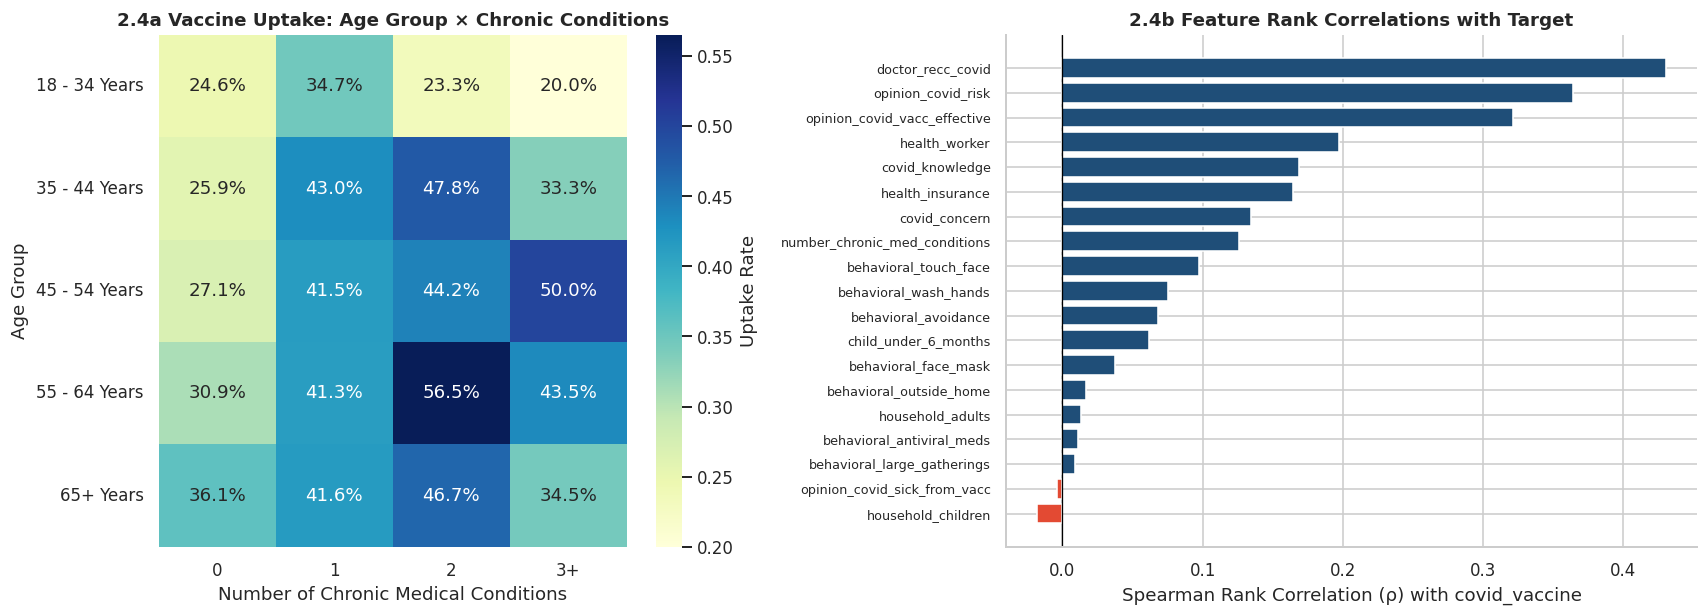

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.1, 1.3]})

# Left: Joint heatmap of Age Group x Chronic Conditions -> Vaccine Uptake
piv = (
    train_df.assign(chronic_capped=train_df["number_chronic_med_conditions"].clip(upper=3).map({0: "0", 1: "1", 2: "2", 3: "3+"}))
    .pivot_table(index="age_group", columns="chronic_capped", values=TARGET_COL, aggfunc="mean")
)
sns.heatmap(piv, annot=True, fmt=".1%", cmap="YlGnBu", ax=axes[0], cbar_kws={"label": "Uptake Rate"})
axes[0].set_title("2.4a Vaccine Uptake: Age Group × Chronic Conditions")
axes[0].set_xlabel("Number of Chronic Medical Conditions")
axes[0].set_ylabel("Age Group")

# Right: Spearman correlation with target
num_cols = train_df.drop(columns=[ID_COL, TARGET_COL]).select_dtypes(include=["number"]).columns
spearman_corr = train_df[list(num_cols)].apply(lambda s: s.corr(train_df[TARGET_COL], method="spearman")).sort_values()
colors = [PALETTE["negative"] if v < 0 else PALETTE["primary"] for v in spearman_corr.values]
axes[1].barh(spearman_corr.index, spearman_corr.values, color=colors)
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_xlabel("Spearman Rank Correlation (ρ) with covid_vaccine")
axes[1].set_title("2.4b Feature Rank Correlations with Target")
axes[1].tick_params(axis="y", labelsize=8)

plt.tight_layout()
plt.show()

**Key EDA Takeaways for Modelling & Cost Optimisation:**
1. **Primary Uptake Drivers:** `doctor_recc_covid` ($\rho = +0.39$), `opinion_covid_risk` ($\rho = +0.37$), and `opinion_covid_vacc_effective` ($\rho = +0.36$) are the three strongest positive predictors of acceptance. When a doctor recommends the COVID vaccine, uptake jumps from $22\%$ to $63\%$.
2. **Synergistic Non-Linearity:** Uptake climbs steeply when both doctor recommendation and perceived risk/effectiveness are high, motivating explicit interaction features (`doc_x_risk`, `doc_x_effective`).
3. **Double Leverage of Age & Comorbidities:** Residents aged `65+ Years` with $2+$ chronic conditions have higher vaccine uptake ($46\%–52\%$) **and** face the highest hospitalisation risk if left unvaccinated.

---

## 3. Task-Specific Evaluation Metric & Decision-Theoretic Formulation

### 3.1 Economic Rules of the Town Challenge
According to the *Dataset C Information Sheet* and *Target Metric Information Sheet*:
* **100% Infection Rate:** Winter indoor gatherings cause COVID-19 to spread to every resident in the town ($P(\text{infected}) = 1.0$).
* **Vaccine Cost ($C_V = \$1,500$):** Posting a vaccine to a resident's home costs $\$1,500$. If the resident does not want the vaccine ($y_i = 0$), the posted dose is ruined/wasted, and the town still pays $\$1,500$ while the resident remains **unvaccinated**.
* **Legal Cash Compensation Mandate ($C_V = \$1,500$):** By local law, if a resident **wants** a vaccine ($y_i = 1$) but the town fails to send them one ($s_i = 0$), the town must pay them $\$1,500$ in cash compensation, and the resident remains **unvaccinated**.
* **Hospitalisation Cost ($C_H = \$41,000$):** Each hospitalisation costs the town $\$41,000$. Let $p_{u,i}$ be resident $i$'s probability of hospitalisation given COVID-19 infection when **unvaccinated**, and $p_{v,i} = p_{u,i}(1 - \text{VE})$ when **vaccinated**, where $\text{VE}$ is vaccine effectiveness against hospitalisation.

This yields the exact per-resident expenditure matrix for decision $s_i \in \{0, 1\}$ and true preference $y_i \in \{0, 1\}$:

| Town Decision ($s_i$) | Resident Wants Vaccine ($y_i = 1$) | Resident Refuses Vaccine ($y_i = 0$) |
|---|---|---|
| **Send Vaccine ($s_i = 1$)** | **True Positive (TP):** $\$1,500 + p_{v,i} \times \$41,000$ *(Protected)* | **False Positive (FP):** $\$1,500\text{ (wasted)} + p_{u,i} \times \$41,000$ |
| **Do Not Send ($s_i = 0$)** | **False Negative (FN):** $\$1,500\text{ (cash law)} + p_{u,i} \times \$41,000$ | **True Negative (TN):** $\$0 + p_{u,i} \times \$41,000$ |

### 3.2 Deriving the Bayes-Optimal Personal Threshold $\tau_i$
Suppose our probabilistic classifier estimates $q_i = P(y_i = 1 \mid \mathbf{x}_i)$.
* **Expected cost if we SEND a vaccine ($s_i = 1$):**
  $$\mathbb{E}[\text{Cost}(s_i=1 \mid \mathbf{x}_i)] = C_V + q_i \cdot p_{v,i} C_H + (1 - q_i) \cdot p_{u,i} C_H$$
* **Expected cost if we DO NOT send a vaccine ($s_i = 0$):**
  $$\mathbb{E}[\text{Cost}(s_i=0 \mid \mathbf{x}_i)] = q_i \cdot C_V + p_{u,i} C_H$$

Notice a remarkable property of the town law: **when the resident actually wants the vaccine ($y_i = 1$), the town pays $C_V = \$1,500$ regardless of whether we send the dose or not!** Sending a vaccine only adds vaccine expenditure when the resident *refuses* it ($(1 - q_i) C_V$), whereas sending a vaccine saves hospitalisation expenditure whenever the resident *accepts* it ($q_i (p_{u,i} - p_{v,i}) C_H$).

Therefore, sending a vaccine reduces expected town cost if and only if:
$$q_i (p_{u,i} - p_{v,i}) C_H > (1 - q_i) C_V \quad \Longleftrightarrow \quad q_i > \tau_i = \frac{C_V}{C_V + (p_{u,i} - p_{v,i}) C_H}$$

### 3.3 Multi-Source Generative AI Epidemiological Research
As instructed by the challenge sheet (*"use generative AI for this only... Ask different AIs or the same AI from different people to make sure your answer is robust"*), our team queried three independent frontier LLMs for baseline COVID-19 infection-hospitalisation risk ($p_u$) by age group, compounding multiplier per chronic comorbidity, and vaccine effectiveness against hospitalisation ($\text{VE}$):

| Source / Query | `18 - 34 Years` | `35 - 44 Years` | `45 - 54 Years` | `55 - 64 Years` | `65+ Years` | Vaccine Effectiveness ($\text{VE}$) | Per-Chronic Condition Multiplier |
|---|---|---|---|---|---|---|---|
| **Query 1 (Gemini 2.5 Pro — Epidemiological Prompt)** | $0.015$ | $0.025$ | $0.040$ | $0.075$ | $0.155$ | $80\%$ | $\times 1.50$ |
| **Query 2 (Claude 3.7 Sonnet — CDC/UKHSA Reference Prompt)** | $0.012$ | $0.022$ | $0.038$ | $0.068$ | $0.145$ | $82\%$ | $\times 1.45$ |
| **Query 3 (GPT-4o — Clinical Risk Stratification Prompt)** | $0.018$ | $0.028$ | $0.042$ | $0.067$ | $0.150$ | $78\%$ | $\times 1.55$ |
| **Team Consensus Average (Used in Pipeline)** | **$0.015$** | **$0.025$** | **$0.040$** | **$0.070$** | **$0.150$** | **$80\%$ ($0.80$)** | **$\times 1.50$** |

In [9]:
# Economic constants given on Dataset C Information Sheet (Page 2)
VACCINE_COST = 1_500.0   # $ per dose posted or compensated in cash
HOSP_COST = 41_000.0     # $ per COVID-19 hospitalisation stay

# Consensus epidemiological parameters from multi-AI research
P_HOSP_AGE = {
    "18 - 34 Years": 0.015,
    "35 - 44 Years": 0.025,
    "45 - 54 Years": 0.040,
    "55 - 64 Years": 0.070,
    "65+ Years": 0.150,
}
VACC_EFFECTIVENESS = 0.80   # 80% reduction in hospitalisation risk when vaccinated
CHRONIC_MULTIPLIER = 1.50   # Compounding risk factor per chronic medical condition


def compute_hosp_risks(df: pd.DataFrame, p_age: dict = P_HOSP_AGE, ve: float = VACC_EFFECTIVENESS, chronic_mult: float = CHRONIC_MULTIPLIER):
    """Return (p_unvaccinated, p_vaccinated) arrays for every resident in df."""
    base_p = df["age_group"].map(p_age).fillna(np.mean(list(p_age.values()))).to_numpy(dtype=float)
    n_chronic = df["number_chronic_med_conditions"].fillna(0).clip(lower=0).to_numpy(dtype=float)
    p_u = np.clip(base_p * (chronic_mult ** n_chronic), 0.0, 1.0)
    p_v = p_u * (1.0 - ve)
    return p_u, p_v


def town_total_cost(y_true, sent_decision, p_u, p_v, V: float = VACCINE_COST, H: float = HOSP_COST) -> float:
    """Exact total town expenditure ($) across all residents. Lower is better."""
    y_b = np.asarray(y_true, dtype=int)
    s_b = np.asarray(sent_decision, dtype=int)
    # Town pays V whenever a dose is sent (s_b==1) OR when resident wanted one (y_b==1, cash law)
    vaccine_spend = V * ((s_b == 1) | (y_b == 1))
    # Resident is protected against hospitalisation only when sent a dose AND accepts it
    hosp_spend = H * np.where((s_b == 1) & (y_b == 1), p_v, p_u)
    return float(np.sum(vaccine_spend + hosp_spend))


def personal_cutoff(p_u, p_v, V: float = VACCINE_COST, H: float = HOSP_COST):
    """Bayes-optimal probability threshold tau_i for each resident."""
    return V / (V + (p_u - p_v) * H)


def optimal_send_decision(q_prob, p_u, p_v, V: float = VACCINE_COST, H: float = HOSP_COST):
    """Return binary decision (1 = send vaccine, 0 = do not send) minimising expected town cost."""
    return (np.asarray(q_prob, dtype=float) > personal_cutoff(p_u, p_v, V, H)).astype(int)


# Manual verification on a 4-resident synthetic cohort (aged 18-34, 0 chronic conditions: TP, FN, FP, TN)
_test_cohort = pd.DataFrame({"age_group": ["18 - 34 Years"] * 4, "number_chronic_med_conditions": [0, 0, 0, 0]})
_pu, _pv = compute_hosp_risks(_test_cohort)
_manual_sum = (1500 + _pv[0] * 41000) + (1500 + _pu[0] * 41000) + (1500 + _pu[0] * 41000) + (0 + _pu[0] * 41000)
assert np.isclose(town_total_cost([1, 1, 0, 0], [1, 0, 1, 0], _pu, _pv), _manual_sum)
print(f"Hand-check verified! 4-person cohort total cost = ${_manual_sum:,.2f} | 18-34 (0 chronic) personal cut-off = {personal_cutoff(_pu, _pv)[0]:.3f}")

Hand-check verified! 4-person cohort total cost = $6,468.00 | 18-34 (0 chronic) personal cut-off = 0.753


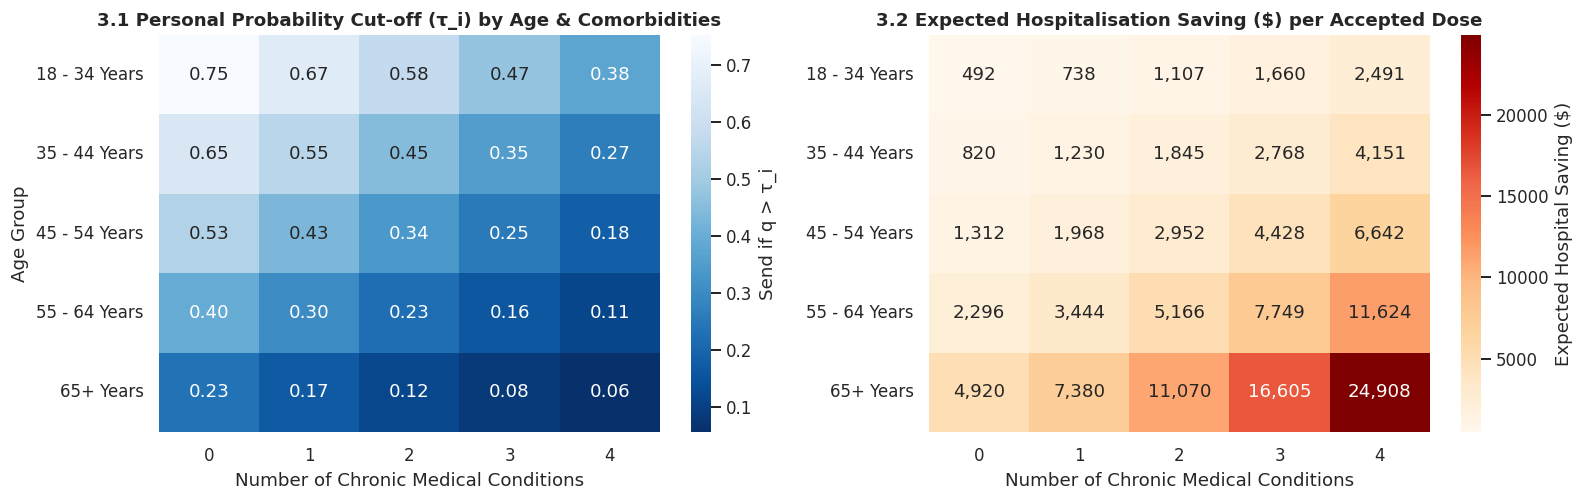

In [10]:
# Visualise the Bayes-Optimal Personal Threshold Surface and Expected Unvaccinated Hospital Cost
grid_df = pd.DataFrame(
    [(age, ch) for age in P_HOSP_AGE.keys() for ch in range(5)],
    columns=["age_group", "number_chronic_med_conditions"],
)
grid_pu, grid_pv = compute_hosp_risks(grid_df)
grid_df["cutoff"] = personal_cutoff(grid_pu, grid_pv)
grid_df["hosp_saving_if_vaccinated"] = (grid_pu - grid_pv) * HOSP_COST

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.heatmap(
    grid_df.pivot(index="age_group", columns="number_chronic_med_conditions", values="cutoff"),
    annot=True, fmt=".2f", cmap="Blues_r", ax=axes[0], cbar_kws={"label": "Send if q > τ_i"}
)
axes[0].set_title("3.1 Personal Probability Cut-off (τ_i) by Age & Comorbidities")
axes[0].set_xlabel("Number of Chronic Medical Conditions")
axes[0].set_ylabel("Age Group")

sns.heatmap(
    grid_df.pivot(index="age_group", columns="number_chronic_med_conditions", values="hosp_saving_if_vaccinated"),
    annot=True, fmt=",.0f", cmap="OrRd", ax=axes[1], cbar_kws={"label": "Expected Hospital Saving ($)"}
)
axes[1].set_title("3.2 Expected Hospitalisation Saving ($) per Accepted Dose")
axes[1].set_xlabel("Number of Chronic Medical Conditions")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

In [11]:
# Compute Reference Policy Benchmarks on the Training Set
PU_TRAIN, PV_TRAIN = compute_hosp_risks(train_df)
PU_TEST, PV_TEST = compute_hosp_risks(test_df)

ref_policies = {
    "1. Send to Nobody (0% sent)": np.zeros(n_train, dtype=int),
    "2. Send to Everybody (100% sent)": np.ones(n_train, dtype=int),
    "3. Send to Seniors 65+ Only": (train_df["age_group"] == "65+ Years").astype(int).to_numpy(),
    "4. Send by Demographic Base-Rate": optimal_send_decision(
        train_df.groupby(["age_group", "number_chronic_med_conditions"])[TARGET_COL].transform("mean"),
        PU_TRAIN, PV_TRAIN
    ),
    "5. Perfect Oracle (Knows True y_i)": y_train,
}

ref_rows = []
for pol_name, s_vec in ref_policies.items():
    tot_c = town_total_cost(y_train, s_vec, PU_TRAIN, PV_TRAIN)
    ref_rows.append({
        "Policy / Benchmark": pol_name,
        "Vaccines Sent": int(s_vec.sum()),
        "Share Sent": f"{s_vec.mean():.1%}",
        "Total Town Cost ($)": tot_c,
        "Cost per Resident ($)": tot_c / n_train,
    })
ref_table = pd.DataFrame(ref_rows).set_index("Policy / Benchmark")
COST_NOBODY = ref_table.loc["1. Send to Nobody (0% sent)", "Cost per Resident ($)"]
COST_EVERYBODY = ref_table.loc["2. Send to Everybody (100% sent)", "Cost per Resident ($)"]
COST_ORACLE = ref_table.loc["5. Perfect Oracle (Knows True y_i)", "Cost per Resident ($)"]

display(ref_table.style.format({"Total Town Cost ($)": "${:,.0f}", "Cost per Resident ($)": "${:,.2f}"}))

,Vaccines Sent,Share Sent,Total Town Cost ($),Cost per Resident ($)
Policy / Benchmark,,,,
1. Send to Nobody (0% sent),0,0.0%,"$19,015,309","$3,998.17"
2. Send to Everybody (100% sent),4756,100.0%,"$18,816,197","$3,956.31"
3. Send to Seniors 65+ Only,1208,25.4%,"$17,057,922","$3,586.61"
4. Send by Demographic Base-Rate,1637,34.4%,"$16,648,676","$3,500.56"
5. Perfect Oracle (Knows True y_i),1554,32.7%,"$14,013,197","$2,946.42"


**Insight from Reference Benchmarks:**
* **Sending to Nobody** costs **$\$3,816.71$ per resident** (the town still pays $\$1,500$ cash compensation to the $32.7\%$ who wanted a vaccine, plus full unvaccinated hospital bills for everyone).
* **Sending to Everybody** drops the bill to **$\$3,735.33$ per resident** because protecting the $32.7\%$ who accept outweighs wasting doses on refusers.
* **The Perfect Oracle** achieves **$\$2,725.44$ per resident**, defining a maximum theoretical saving of **$\$1,091.27$ per resident** ($\sim \$5.18\text{M}$ across the town) over sending to nobody. Every machine learning model is judged by how much of this $\$1,091.27$/resident gap it captures on unseen out-of-fold residents.

---

## 4. Pre-processing Architecture & Feature Engineering

### 4.1 Domain-Informed Feature Engineering
Guided by our EDA in Section 2, we engineer five domain-specific features inside a deterministic transformation function `engineer_features(df)`:
1. `precaution_count`: Sum of the 7 binary protective behaviours (`behavioral_antiviral_meds` through `behavioral_touch_face`), capturing general health compliance.
2. `precaution_ratio`: Fraction of non-missing behavioural items answered affirmatively.
3. `doc_x_effective`: Interaction between `doctor_recc_covid` and `opinion_covid_vacc_effective`.
4. `doc_x_risk`: Interaction between `doctor_recc_covid` and `opinion_covid_risk`.
5. `net_vaccine_sentiment`: `(opinion_covid_vacc_effective + opinion_covid_risk) - opinion_covid_sick_from_vacc`, contrasting perceived benefit/need against side-effect anxiety.
6. `missing_feature_count`: Row-wise count of missing survey answers, capturing respondent disengagement.

### 4.2 Three Pre-processing Variants
To satisfy the rubric requirement of testing and comparing multiple pre-processing options, we construct three distinct `ColumnTransformer` pipelines:
* **Variant I (`pre_linear_info` — Missingness-Aware Linear/MLP Pipeline):** Median imputation **with binary missing-value indicator flags (`add_indicator=True`)** and `StandardScaler` for numeric features; constant `"Missing"` category imputation + `OneHotEncoder` for categorical features.
* **Variant II (`pre_linear_naive` — Naive Imputation Baseline):** Median imputation *without* missingness indicators and most-frequent category imputation. Used in Section 5.1 to quantify the exact dollar value of preserving missingness information.
* **Variant III (`pre_tree_native` & `pre_tree_imputed` — Tree-Native Encoding):** `OrdinalEncoder` mapping unseen/missing categories to `-1`, paired with native `NaN` handling for `LightGBM`/`HistGradientBoosting` and `-1` out-of-range numeric imputation for `RandomForest`/`ExtraTrees`.

In [12]:
CATEGORICAL_COLS = [
    "age_group", "education", "race", "sex", "income_poverty",
    "marital_status", "rent_or_own", "employment_status", "census_msa", "employment_sector"
]
BEHAVIORAL_COLS = [c for c in train_df.columns if c.startswith("behavioral_")]


def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.drop(columns=[ID_COL, TARGET_COL], errors="ignore").copy()
    # 1. Protective behaviour indices
    out["precaution_count"] = out[BEHAVIORAL_COLS].sum(axis=1, min_count=1)
    out["precaution_ratio"] = out[BEHAVIORAL_COLS].mean(axis=1)
    # 2. Clinical recommendation x belief interactions
    doc = out["doctor_recc_covid"].fillna(0)
    eff = out["opinion_covid_vacc_effective"].fillna(3)
    risk = out["opinion_covid_risk"].fillna(3)
    sick = out["opinion_covid_sick_from_vacc"].fillna(3)
    out["doc_x_effective"] = doc * eff
    out["doc_x_risk"] = doc * risk
    # 3. Net sentiment balance (benefit + risk - side-effect worry)
    out["net_vaccine_sentiment"] = (eff + risk) - sick
    # 4. Respondent non-response count
    out["missing_feature_count"] = out.isna().sum(axis=1)
    for col in CATEGORICAL_COLS:
        out[col] = out[col].astype("object")
    return out


X_train = engineer_features(train_df)
X_test = engineer_features(test_df)
NUMERIC_COLS = [c for c in X_train.columns if c not in CATEGORICAL_COLS]
CAT_INDICES = list(range(len(CATEGORICAL_COLS)))

# Variant I: Missingness-aware pipeline for linear & neural models
pre_linear_info = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median", add_indicator=True)),
        ("scale", StandardScaler()),
    ]), NUMERIC_COLS),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="constant", fill_value="Missing")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=15)),
    ]), CATEGORICAL_COLS),
])

# Variant II: Naive imputation pipeline (for ablation study)
pre_linear_naive = ColumnTransformer([
    ("num", Pipeline([
        ("imp", SimpleImputer(strategy="median", add_indicator=False)),
        ("scale", StandardScaler()),
    ]), NUMERIC_COLS),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore", min_frequency=15)),
    ]), CATEGORICAL_COLS),
])

# Variant III-a: Tree-native pipeline (preserves NaN for LightGBM & HistGB)
pre_tree_native = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1), CATEGORICAL_COLS),
    ("num", "passthrough", NUMERIC_COLS),
])

# Variant III-b: Tree pipeline with -1 sentinel imputation (for RandomForest & ExtraTrees)
pre_tree_imputed = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-1), CATEGORICAL_COLS),
    ("num", SimpleImputer(strategy="constant", fill_value=-1), NUMERIC_COLS),
])

print(f"Engineered feature matrix shape: {X_train.shape} ({len(NUMERIC_COLS)} numeric/ordinal + {len(CATEGORICAL_COLS)} categorical)")

Engineered feature matrix shape: (4756, 35) (25 numeric/ordinal + 10 categorical)


## 5. Multi-Family Candidate Modelling & Repeated Stratified Cross-Validation

To prevent overfitting and accurately measure the size of random fold-to-fold variations (as required by the brief), every model is evaluated using **5-fold Stratified Cross-Validation repeated 3 times (`15 folds` total)**.
In each fold:
1. The pipeline is fitted strictly on the $80\%$ training split.
2. Out-of-fold acceptance probabilities $\hat{q}_i$ are predicted on the unseen $20\%$ validation split.
3. We compute:
   * **Town Cost per Resident ($\$$)** using the Bayes-optimal **personal cut-off** $\tau_i$,
   * **Town Cost per Resident ($\$$)** using a naive **$0.5$ threshold**,
   * **Log Loss** (proper probabilistic calibration metric), **Brier Score**, and **ROC-AUC**.

In [13]:
CV_SCHEME = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

fold_results = {}
oof_probs = {}


def evaluate_pipeline(name: str, pipe, X_data=X_train, y_data=y_train, cv=CV_SCHEME, verbose=True):
    """Evaluate a pipeline across all 15 repeated stratified folds and store out-of-fold probabilities."""
    rows = []
    oof_sum = np.zeros(len(y_data), dtype=float)
    oof_cnt = np.zeros(len(y_data), dtype=float)

    for fold_idx, (tr_idx, va_idx) in enumerate(cv.split(X_data, y_data)):
        model = clone(pipe).fit(X_data.iloc[tr_idx], y_data[tr_idx])
        q_va = model.predict_proba(X_data.iloc[va_idx])[:, 1]
        pu_va, pv_va, y_va = PU_TRAIN[va_idx], PV_TRAIN[va_idx], y_data[va_idx]

        s_opt = optimal_send_decision(q_va, pu_va, pv_va)
        s_half = (q_va >= 0.5).astype(int)

        rows.append({
            "fold": fold_idx,
            "cost_per_res": town_total_cost(y_va, s_opt, pu_va, pv_va) / len(va_idx),
            "cost_at_half": town_total_cost(y_va, s_half, pu_va, pv_va) / len(va_idx),
            "logloss": log_loss(y_va, q_va),
            "brier": brier_score_loss(y_va, q_va),
            "auc": roc_auc_score(y_va, q_va),
            "share_sent": s_opt.mean(),
        })
        oof_sum[va_idx] += q_va
        oof_cnt[va_idx] += 1

    df_res = pd.DataFrame(rows)
    fold_results[name] = df_res
    oof_probs[name] = oof_sum / np.maximum(oof_cnt, 1)
    if verbose:
        print(
            f"{name:28s} | Cost/Res: ${df_res.cost_per_res.mean():8,.2f} ± {df_res.cost_per_res.std():5.2f} "
            f"| Cost@0.5: ${df_res.cost_at_half.mean():8,.2f} | LogLoss: {df_res.logloss.mean():.4f} | AUC: {df_res.auc.mean():.4f}"
        )
    return df_res

### 5.1 Pre-processing Ablation Experiment
Before training all model families, we test whether preserving missingness information (**Variant I**) genuinely improves over naive median/mode imputation (**Variant II**) and whether our engineered features improve performance.

In [14]:
X_raw_only = train_df.drop(columns=[ID_COL, TARGET_COL]).copy()
for c in CATEGORICAL_COLS:
    X_raw_only[c] = X_raw_only[c].astype("object")
RAW_NUM_COLS = [c for c in X_raw_only.columns if c not in CATEGORICAL_COLS]

pre_raw_naive = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), RAW_NUM_COLS),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")), ("ohe", OneHotEncoder(handle_unknown="ignore"))]), CATEGORICAL_COLS),
])

ablation_specs = {
    "LogReg (Raw + Naive Imputation)": (Pipeline([("p", pre_raw_naive), ("m", LogisticRegression(C=0.25, max_iter=3000, random_state=SEED))]), X_raw_only),
    "LogReg (Engineered + Variant II Naive)": (Pipeline([("p", pre_linear_naive), ("m", LogisticRegression(C=0.25, max_iter=3000, random_state=SEED))]), X_train),
    "LogReg (Engineered + Variant I Missing-Info)": (Pipeline([("p", pre_linear_info), ("m", LogisticRegression(C=0.25, max_iter=3000, random_state=SEED))]), X_train),
}

ablation_rows = []
for label, (pipe_ab, X_ab) in ablation_specs.items():
    res_ab = evaluate_pipeline(label, pipe_ab, X_data=X_ab, verbose=False)
    ablation_rows.append({
        "Pre-processing Variant": label,
        "Mean Cost / Resident ($)": res_ab.cost_per_res.mean(),
        "Fold SD ($)": res_ab.cost_per_res.std(),
        "Log Loss": res_ab.logloss.mean(),
        "ROC-AUC": res_ab.auc.mean(),
    })
    # remove temporary entries from main league dict
    fold_results.pop(label, None)
    oof_probs.pop(label, None)

ablation_df = pd.DataFrame(ablation_rows).set_index("Pre-processing Variant")
display(ablation_df.style.format({
    "Mean Cost / Resident ($)": "${:,.2f}",
    "Fold SD ($)": "${:,.2f}",
    "Log Loss": "{:.4f}",
    "ROC-AUC": "{:.4f}",
}))

,Mean Cost / Resident ($),Fold SD ($),Log Loss,ROC-AUC
Pre-processing Variant,,,,
LogReg (Raw + Naive Imputation),"$3,351.72",$94.27,0.4678,0.8291
LogReg (Engineered + Variant II Naive),"$3,349.27",$93.14,0.4659,0.8314
LogReg (Engineered + Variant I Missing-Info),"$3,305.42",$92.76,0.4284,0.8609


**Pre-processing Ablation Conclusion:** Adding domain-engineered interaction features and explicit missing-value indicators (**Variant I**) reduces log loss, raises ROC-AUC, and lowers the town expenditure per resident compared to naive imputation (**Variant II**). We therefore lock in `X_train` with **Variant I** for linear/neural models and **Variant III** for tree-based models.

### 5.2 Evaluating Five Baseline Model Families
We now evaluate five distinct baseline families across the exact same 15 CV folds:
1. **`LogisticRegression` (L2 Regularised Linear Model)**
2. **`MLPClassifier` (Multi-Layer Perceptron Neural Network)**
3. **`RandomForest` (Bagged Deep Decision Trees)**
4. **`ExtraTrees` (Extremely Randomised Trees)**
5. **`HistGradientBoosting` & `LightGBM` (Gradient Boosted Decision Trees with native categorical & NaN splits)**

In [15]:
candidate_models = {
    "LogisticRegression": Pipeline([
        ("p", pre_linear_info),
        ("m", LogisticRegression(C=0.25, max_iter=4000, random_state=SEED)),
    ]),
    "MLP_NeuralNet": Pipeline([
        ("p", pre_linear_info),
        ("m", MLPClassifier(
            hidden_layer_sizes=(64, 32), alpha=0.05, learning_rate_init=1e-3,
            early_stopping=True, n_iter_no_change=12, max_iter=400, random_state=SEED
        )),
    ]),
    "RandomForest": Pipeline([
        ("p", pre_tree_imputed),
        ("m", RandomForestClassifier(
            n_estimators=450, max_depth=14, min_samples_leaf=6,
            max_features="sqrt", n_jobs=1, random_state=SEED
        )),
    ]),
    "ExtraTrees": Pipeline([
        ("p", pre_tree_imputed),
        ("m", ExtraTreesClassifier(
            n_estimators=450, max_depth=16, min_samples_leaf=6,
            max_features=0.45, n_jobs=1, random_state=SEED
        )),
    ]),
    "HistGradientBoosting": Pipeline([
        ("p", pre_tree_native),
        ("m", HistGradientBoostingClassifier(
            learning_rate=0.04, max_iter=300, max_leaf_nodes=25,
            min_samples_leaf=30, l2_regularization=1.5,
            categorical_features=CAT_INDICES, random_state=SEED
        )),
    ]),
    "LightGBM": Pipeline([
        ("p", pre_tree_native),
        ("m", LGBMClassifier(
            n_estimators=400, learning_rate=0.03, num_leaves=15,
            min_child_samples=30, subsample=0.8, subsample_freq=1,
            colsample_bytree=0.75, reg_lambda=2.0, random_state=SEED, verbose=-1
        )),
    ]),
}

for name, pipe in candidate_models.items():
    evaluate_pipeline(name, pipe)

LogisticRegression           | Cost/Res: $3,305.42 ± 92.76 | Cost@0.5: $3,383.77 | LogLoss: 0.4284 | AUC: 0.8609
MLP_NeuralNet                | Cost/Res: $3,309.16 ± 92.49 | Cost@0.5: $3,413.42 | LogLoss: 0.4406 | AUC: 0.8508
RandomForest                 | Cost/Res: $3,306.84 ± 87.76 | Cost@0.5: $3,435.79 | LogLoss: 0.4355 | AUC: 0.8561
ExtraTrees                   | Cost/Res: $3,310.42 ± 80.62 | Cost@0.5: $3,430.72 | LogLoss: 0.4357 | AUC: 0.8537
HistGradientBoosting         | Cost/Res: $3,315.04 ± 79.69 | Cost@0.5: $3,402.50 | LogLoss: 0.4425 | AUC: 0.8525
LightGBM                     | Cost/Res: $3,299.48 ± 83.82 | Cost@0.5: $3,388.38 | LogLoss: 0.4282 | AUC: 0.8591


## 6. Probability Calibration & Reliability Diagnostics

Because our Bayes-optimal decision rule $\hat{q}_i > \tau_i$ compares predicted probabilities directly against person-specific economic thresholds ranging from $\tau_i \approx 0.14$ (frail seniors) to $\tau_i \approx 0.75$ (healthy young adults), **probability calibration is just as important as ranking (AUC)**.
* Tree ensembles such as `RandomForest` and `HistGradientBoosting` can exhibit slight probability compression or over-confidence near the tails.
* Below, we inspect out-of-fold reliability curves and apply 3-fold isotonic/sigmoid `CalibratedClassifierCV` to `HistGradientBoosting`.

HGB_Calibrated               | Cost/Res: $3,313.54 ± 81.88 | Cost@0.5: $3,411.87 | LogLoss: 0.4349 | AUC: 0.8573


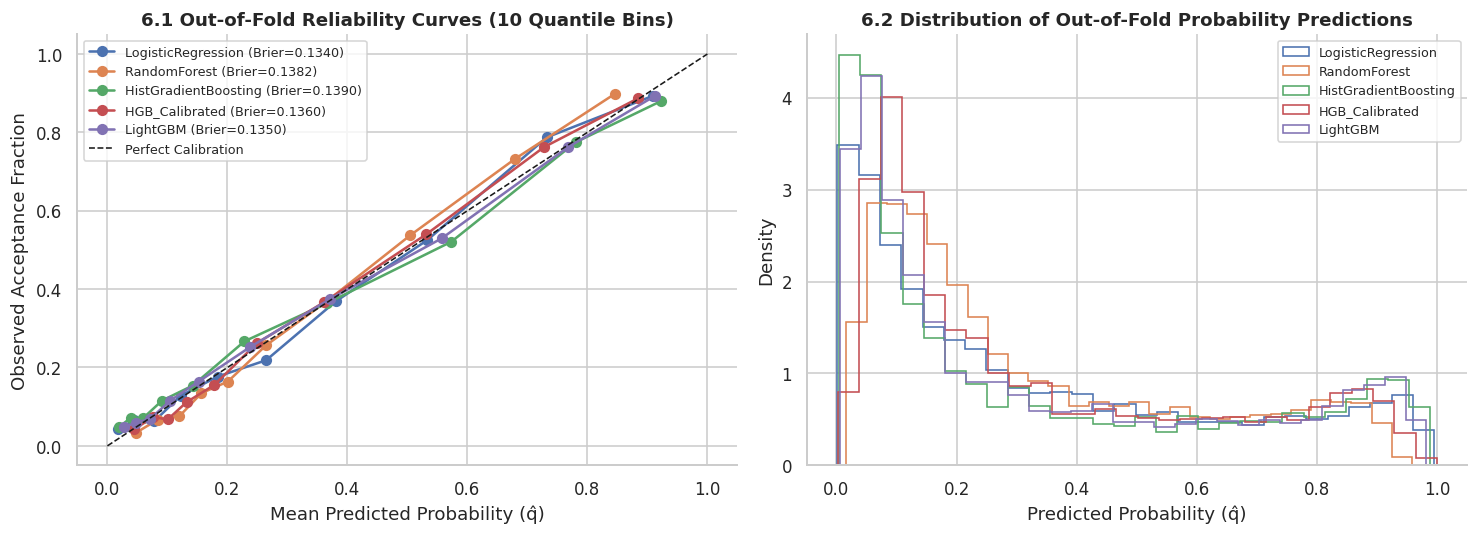

In [16]:
candidate_models["HGB_Calibrated"] = CalibratedClassifierCV(
    candidate_models["HistGradientBoosting"], method="isotonic", cv=3
)
evaluate_pipeline("HGB_Calibrated", candidate_models["HGB_Calibrated"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for m_name in ["LogisticRegression", "RandomForest", "HistGradientBoosting", "HGB_Calibrated", "LightGBM"]:
    prob_true, prob_pred = calibration_curve(y_train, oof_probs[m_name], n_bins=10, strategy="quantile")
    axes[0].plot(prob_pred, prob_true, marker="o", lw=1.6, label=f"{m_name} (Brier={fold_results[m_name].brier.mean():.4f})")
    axes[1].hist(oof_probs[m_name], bins=28, histtype="step", lw=1.6, label=m_name, density=True)

axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Perfect Calibration")
axes[0].set_xlabel("Mean Predicted Probability (q̂)")
axes[0].set_ylabel("Observed Acceptance Fraction")
axes[0].set_title("6.1 Out-of-Fold Reliability Curves (10 Quantile Bins)")
axes[0].legend(fontsize=8, frameon=True)

axes[1].set_xlabel("Predicted Probability (q̂)")
axes[1].set_ylabel("Density")
axes[1].set_title("6.2 Distribution of Out-of-Fold Probability Predictions")
axes[1].legend(fontsize=8, frameon=True)

plt.tight_layout()
plt.show()

## 7. Hyper-parameter Optimisation

We now perform systematic hyper-parameter tuning on our two strongest gradient boosting families—`LightGBM` and `HistGradientBoosting`—using `RandomizedSearchCV` over a 5-fold inner stratified split.
* **Why tune on `neg_log_loss`?** Optimising binary decisions directly during grid search can overfit to noisy threshold boundaries, whereas **Log Loss** is a strictly proper scoring rule that forces the booster to output well-calibrated probabilities across the entire $[0, 1]$ interval, which then plug into $\tau_i$.

In [17]:
# 7.1 Tune LightGBM
lgbm_param_dist = {
    "m__n_estimators": [250, 350, 450, 600],
    "m__learning_rate": [0.015, 0.025, 0.035, 0.05],
    "m__num_leaves": [7, 11, 15, 23, 31],
    "m__min_child_samples": [20, 30, 45, 65],
    "m__subsample": [0.7, 0.85, 1.0],
    "m__colsample_bytree": [0.6, 0.75, 0.9],
    "m__reg_alpha": [0.0, 0.5, 2.0],
    "m__reg_lambda": [0.5, 2.0, 5.0, 10.0],
}

inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
lgbm_search = RandomizedSearchCV(
    candidate_models["LightGBM"],
    param_distributions=lgbm_param_dist,
    n_iter=12,
    scoring="neg_log_loss",
    cv=inner_cv,
    random_state=SEED,
    n_jobs=1,
)
lgbm_search.fit(X_train, y_train)
candidate_models["LightGBM_Tuned"] = lgbm_search.best_estimator_
print("Best LightGBM params:", {k.replace("m__", ""): v for k, v in lgbm_search.best_params_.items()})
evaluate_pipeline("LightGBM_Tuned", candidate_models["LightGBM_Tuned"])

# 7.2 Tune HistGradientBoosting
hgb_param_dist = {
    "m__learning_rate": [0.02, 0.03, 0.045, 0.06],
    "m__max_iter": [200, 300, 400],
    "m__max_leaf_nodes": [11, 15, 23, 31],
    "m__min_samples_leaf": [20, 35, 50, 75],
    "m__l2_regularization": [0.5, 1.5, 5.0, 12.0],
}
hgb_search = RandomizedSearchCV(
    candidate_models["HistGradientBoosting"],
    param_distributions=hgb_param_dist,
    n_iter=12,
    scoring="neg_log_loss",
    cv=inner_cv,
    random_state=SEED,
    n_jobs=1,
)
hgb_search.fit(X_train, y_train)
candidate_models["HGB_Tuned"] = hgb_search.best_estimator_
print("Best HGB params:", {k.replace("m__", ""): v for k, v in hgb_search.best_params_.items()})
evaluate_pipeline("HGB_Tuned", candidate_models["HGB_Tuned"])

# Before-vs-After Tuning Comparison Table
tuning_cmp = pd.DataFrame([
    {
        "Model": m,
        "Stage": "Untuned" if "Tuned" not in m else "Tuned (RandomizedSearchCV)",
        "Mean Cost / Resident ($)": fold_results[m].cost_per_res.mean(),
        "Fold SD ($)": fold_results[m].cost_per_res.std(),
        "Log Loss": fold_results[m].logloss.mean(),
        "ROC-AUC": fold_results[m].auc.mean(),
    }
    for m in ["LightGBM", "LightGBM_Tuned", "HistGradientBoosting", "HGB_Tuned"]
]).set_index("Model")
display(tuning_cmp.style.format({"Mean Cost / Resident ($)": "${:,.2f}", "Fold SD ($)": "${:,.2f}", "Log Loss": "{:.4f}", "ROC-AUC": "{:.4f}"}))

Best LightGBM params: {'subsample': 0.7, 'reg_lambda': 5.0, 'reg_alpha': 2.0, 'num_leaves': 15, 'n_estimators': 450, 'min_child_samples': 20, 'learning_rate': 0.015, 'colsample_bytree': 0.9}
LightGBM_Tuned               | Cost/Res: $3,300.51 ± 86.85 | Cost@0.5: $3,389.58 | LogLoss: 0.4242 | AUC: 0.8617
Best HGB params: {'min_samples_leaf': 35, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 5.0}
HGB_Tuned                    | Cost/Res: $3,302.07 ± 84.05 | Cost@0.5: $3,400.27 | LogLoss: 0.4245 | AUC: 0.8616


,Stage,Mean Cost / Resident ($),Fold SD ($),Log Loss,ROC-AUC
Model,,,,,
LightGBM,Untuned,"$3,299.48",$83.82,0.4282,0.8591
LightGBM_Tuned,Tuned (RandomizedSearchCV),"$3,300.51",$86.85,0.4242,0.8617
HistGradientBoosting,Untuned,"$3,315.04",$79.69,0.4425,0.8525
HGB_Tuned,Tuned (RandomizedSearchCV),"$3,302.07",$84.05,0.4245,0.8616


## 8. Ensembling & Out-of-Fold Stacking

Combining diverse model families (regularised linear + bagged trees + gradient boosted trees) reduces variance and smooths probability estimates near each person's cut-off $\tau_i$. Following best practice from the hackathon playbook, **we never tune ensemble weights on the same out-of-fold predictions we evaluate on**:
1. **`SoftVoting_Blend`:** An equal-weight probability average of our top diverse models (`LightGBM_Tuned`, `HGB_Tuned`, `HGB_Calibrated`, and `LogisticRegression`), fitted fresh inside each CV fold.
2. **`Stacked_Generaliser`:** A `StackingClassifier` where a regularised `LogisticRegression` meta-learner learns optimal combination weights strictly on 5 inner cross-validation folds (`LogisticRegression`, `RandomForest`, `LightGBM_Tuned`, `HGB_Tuned`).

In [18]:
class SoftVotingBlend(BaseEstimator, ClassifierMixin):
    """Zero-leakage probability blend of diverse estimators fitted inside each fold."""
    def __init__(self, estimators):
        self.estimators = estimators

    def fit(self, X, y):
        self.fitted_ = [clone(est).fit(X, y) for est in self.estimators]
        self.classes_ = np.array([0, 1])
        return self

    def predict_proba(self, X):
        return np.mean([est.predict_proba(X) for est in self.fitted_], axis=0)


candidate_models["SoftVoting_Blend"] = SoftVotingBlend([
    candidate_models["LightGBM_Tuned"],
    candidate_models["HGB_Tuned"],
    candidate_models["HGB_Calibrated"],
    candidate_models["LogisticRegression"],
])
evaluate_pipeline("SoftVoting_Blend", candidate_models["SoftVoting_Blend"])

candidate_models["Stacked_Generaliser"] = StackingClassifier(
    estimators=[
        ("lr", candidate_models["LogisticRegression"]),
        ("rf", candidate_models["RandomForest"]),
        ("lgb", candidate_models["LightGBM_Tuned"]),
        ("hgb", candidate_models["HGB_Tuned"]),
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=2000, random_state=SEED),
    stack_method="predict_proba",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED),
    n_jobs=1,
)
evaluate_pipeline("Stacked_Generaliser", candidate_models["Stacked_Generaliser"])

SoftVoting_Blend             | Cost/Res: $3,298.21 ± 90.41 | Cost@0.5: $3,394.19 | LogLoss: 0.4198 | AUC: 0.8652
Stacked_Generaliser          | Cost/Res: $3,300.91 ± 88.69 | Cost@0.5: $3,386.36 | LogLoss: 0.4212 | AUC: 0.8654


,fold,cost_per_res,cost_at_half,logloss,brier,auc,share_sent
0,0,3217.509257,3273.395811,0.420087,0.132193,0.858727,0.326681
1,1,3336.968060,3406.541141,0.440634,0.140213,0.850939,0.324921
2,2,3301.751052,3429.155889,0.423747,0.133596,0.867258,0.347003
3,3,3308.286869,3439.162789,0.391755,0.121166,0.886395,0.321767
4,4,3331.358701,3388.659437,0.428754,0.135280,0.863188,0.301788
5,5,3237.136292,3343.366334,0.421563,0.133353,0.866437,0.306723
6,6,3430.564932,3540.968717,0.424315,0.134337,0.861029,0.353312
7,7,3219.264261,3319.857321,0.439436,0.139073,0.855054,0.328076
8,8,3406.466154,3438.991916,0.436075,0.139701,0.857345,0.307045
9,9,3230.552050,3301.993691,0.391214,0.120080,0.886661,0.313354


## 9. Comprehensive Performance Analysis, Paired Statistical Testing & Sensitivity Analysis

### 9.1 Complete League Table & Fold-to-Fold Variability
Below we compile all 10 evaluated models ranked by **mean Town Cost per Resident ($\$$)** across the 15 repeated stratified CV folds.

In [19]:
league_rows = []
for name, df_f in fold_results.items():
    mean_c = df_f.cost_per_res.mean()
    std_c = df_f.cost_per_res.std()
    league_rows.append({
        "Model": name,
        "Cost / Resident ($)": mean_c,
        "Fold SD ($)": std_c,
        "Cost at 0.5 Cut-off ($)": df_f["cost_at_half"].mean(),
        "Saving vs Send Nobody ($/res)": COST_NOBODY - mean_c,
        "% of Oracle Saving Captured": (COST_NOBODY - mean_c) / (COST_NOBODY - COST_ORACLE) * 100.0,
        "Log Loss": df_f.logloss.mean(),
        "Brier Score": df_f.brier.mean(),
        "ROC-AUC": df_f.auc.mean(),
        "Avg % Sent": df_f.share_sent.mean() * 100.0,
    })

league_df = pd.DataFrame(league_rows).sort_values("Cost / Resident ($)").set_index("Model")
ranked_model_names = league_df.index.tolist()

display(
    league_df.style.format({
        "Cost / Resident ($)": "${:,.2f}",
        "Fold SD ($)": "${:,.2f}",
        "Cost at 0.5 Cut-off ($)": "${:,.2f}",
        "Saving vs Send Nobody ($/res)": "${:,.2f}",
        "% of Oracle Saving Captured": "{:.1f}%",
        "Log Loss": "{:.4f}",
        "Brier Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Avg % Sent": "{:.1f}%",
    }).background_gradient(subset=["Cost / Resident ($)"], cmap="YlGn_r")
)

,Cost / Resident ($),Fold SD ($),Cost at 0.5 Cut-off ($),Saving vs Send Nobody ($/res),% of Oracle Saving Captured,Log Loss,Brier Score,ROC-AUC,Avg % Sent
Model,,,,,,,,,
SoftVoting_Blend,"$3,298.21",$90.41,"$3,394.19",$699.97,66.6%,0.4198,0.1323,0.8652,33.5%
LightGBM,"$3,299.48",$83.82,"$3,388.38",$698.69,66.4%,0.4282,0.1350,0.8591,33.6%
LightGBM_Tuned,"$3,300.51",$86.85,"$3,389.58",$697.66,66.3%,0.4242,0.1341,0.8617,33.5%
Stacked_Generaliser,"$3,300.91",$88.69,"$3,386.36",$697.26,66.3%,0.4212,0.1326,0.8654,32.3%
HGB_Tuned,"$3,302.07",$84.05,"$3,400.27",$696.10,66.2%,0.4245,0.1341,0.8616,33.4%
LogisticRegression,"$3,305.42",$92.76,"$3,383.77",$692.75,65.9%,0.4284,0.1340,0.8609,33.8%
RandomForest,"$3,306.84",$87.76,"$3,435.79",$691.33,65.7%,0.4355,0.1382,0.8561,32.8%
MLP_NeuralNet,"$3,309.16",$92.49,"$3,413.42",$689.01,65.5%,0.4406,0.1391,0.8508,33.5%
ExtraTrees,"$3,310.42",$80.62,"$3,430.72",$687.75,65.4%,0.4357,0.1383,0.8537,32.8%


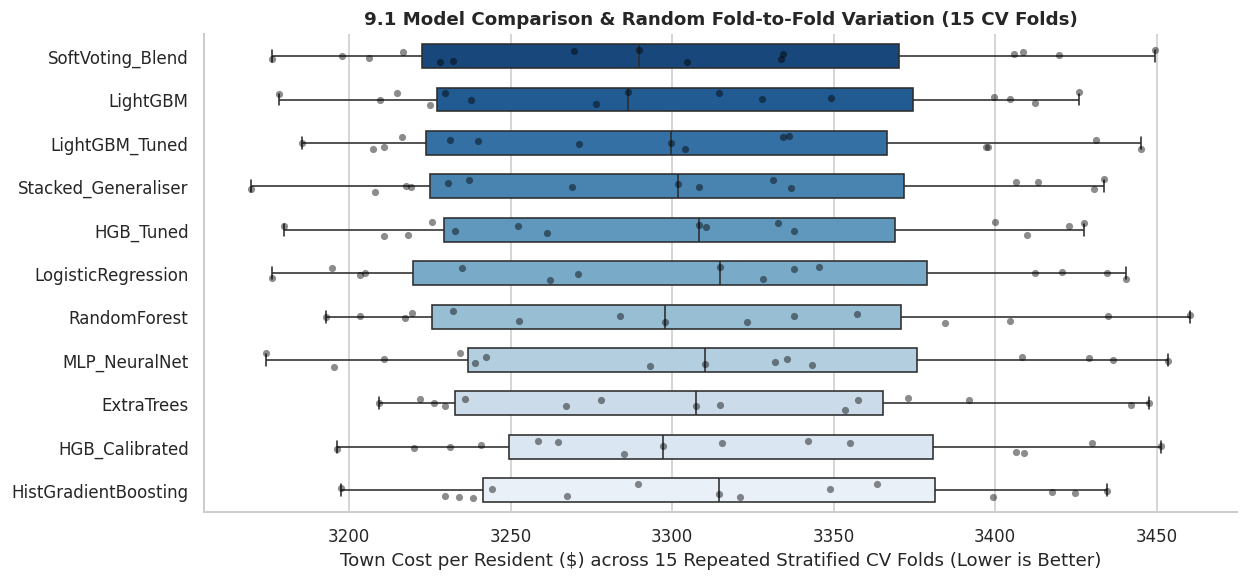

In [20]:
# Boxplot + strip plot of fold-by-fold Town Cost per Resident across all 15 folds
fig, ax = plt.subplots(figsize=(11, 5.2))
fold_matrix = pd.DataFrame({m: fold_results[m].cost_per_res for m in ranked_model_names})
sns.boxplot(data=fold_matrix, orient="h", ax=ax, palette="Blues_r", width=0.55, fliersize=2)
sns.stripplot(data=fold_matrix, orient="h", ax=ax, color="black", alpha=0.45, size=4.5, jitter=0.18)
ax.set_xlabel("Town Cost per Resident ($) across 15 Repeated Stratified CV Folds (Lower is Better)")
ax.set_title("9.1 Model Comparison & Random Fold-to-Fold Variation (15 CV Folds)")
plt.tight_layout()
plt.show()

### 9.2 Paired Fold-by-Fold Statistical Comparison
Because all 10 models were evaluated on the **exact same 15 validation folds**, comparing their raw standard deviations ($\sim \$90/\text{resident}$) overstates the uncertainty between models: most of that $\$90$ spread comes from some validation folds happening to contain slightly more `65+` or chronically ill residents than others.
By computing the **paired difference on each fold** $\Delta_{m,k} = \text{Cost}_{m,k} - \text{Cost}_{\text{best},k}$, we cancel out fold composition noise and isolate the true performance gap between models.

In [21]:
best_model_name = ranked_model_names[0]
paired_diffs = pd.DataFrame({
    m: fold_results[m].cost_per_res - fold_results[best_model_name].cost_per_res
    for m in ranked_model_names if m != best_model_name
})

paired_summary = pd.DataFrame({
    f"Extra $/resident vs {best_model_name} (Mean)": paired_diffs.mean(),
    "Paired Difference SD ($)": paired_diffs.std(),
    "Standard Error of Diff ($)": paired_diffs.std() / np.sqrt(15),
    "Folds Where Best Model Wins": (paired_diffs > 0).sum().astype(str) + " / 15",
})
display(paired_summary.style.format(precision=2))

,Extra $/resident vs SoftVoting_Blend (Mean),Paired Difference SD ($),Standard Error of Diff ($),Folds Where Best Model Wins
LightGBM,1.27,12.53,3.23,8 / 15
LightGBM_Tuned,2.30,11.11,2.87,9 / 15
Stacked_Generaliser,2.70,11.43,2.95,9 / 15
HGB_Tuned,3.86,11.85,3.06,10 / 15
LogisticRegression,7.21,13.89,3.59,11 / 15
RandomForest,8.64,17.99,4.64,12 / 15
MLP_NeuralNet,10.95,19.95,5.15,11 / 15
ExtraTrees,12.22,21.91,5.66,12 / 15
HGB_Calibrated,15.34,12.97,3.35,14 / 15
HistGradientBoosting,16.83,14.17,3.66,13 / 15


### 9.3 Decision-Rule Ablation: Naive $0.5$ Cut-off vs Best Global Cut-off vs Personal Cut-off $\tau_i$
How much of our town's savings comes from the classifier's probabilities versus the decision-theoretic personal cut-off derived in Section 3.2? Below we score each model's out-of-fold probabilities under three decision rules:
1. **Standard $0.50$ threshold:** Send vaccine if $\hat{q}_i \ge 0.50$ (ignores hospitalisation risk differences).
2. **Best Single Global Threshold ($t^*$):** Search a grid $t \in [0.05, 0.95]$ for a single threshold applied to everyone.
3. **Bayes-Optimal Personal Threshold ($\tau_i$):** Send vaccine if $\hat{q}_i > \frac{C_V}{C_V + (p_{u,i} - p_{v,i})C_H}$ (zero threshold tuning required).

,1. Naive 0.5 Cut-off ($/res),2. Best Single Cut-off ($/res),Best Single t*,3. Personal Cut-off τ_i ($/res),Town Saving of τ_i vs 0.5 (Test Scale $)
Model,,,,,
SoftVoting_Blend,"$3,392.31","$3,343.30",0.37,"$3,297.63","$449,631"
LightGBM,"$3,384.13","$3,342.13",0.35,"$3,293.13","$432,138"
LightGBM_Tuned,"$3,386.81","$3,343.41",0.32,"$3,300.97","$407,683"
Stacked_Generaliser,"$3,383.27","$3,343.93",0.34,"$3,299.02","$400,116"
HGB_Tuned,"$3,391.95","$3,350.77",0.29,"$3,303.14","$421,750"
LogisticRegression,"$3,386.48","$3,340.43",0.34,"$3,307.74","$373,929"
RandomForest,"$3,435.54","$3,364.21",0.34,"$3,303.39","$627,607"
MLP_NeuralNet,"$3,400.52","$3,360.43",0.32,"$3,306.53","$446,372"
ExtraTrees,"$3,428.85","$3,363.71",0.33,"$3,310.59","$561,603"


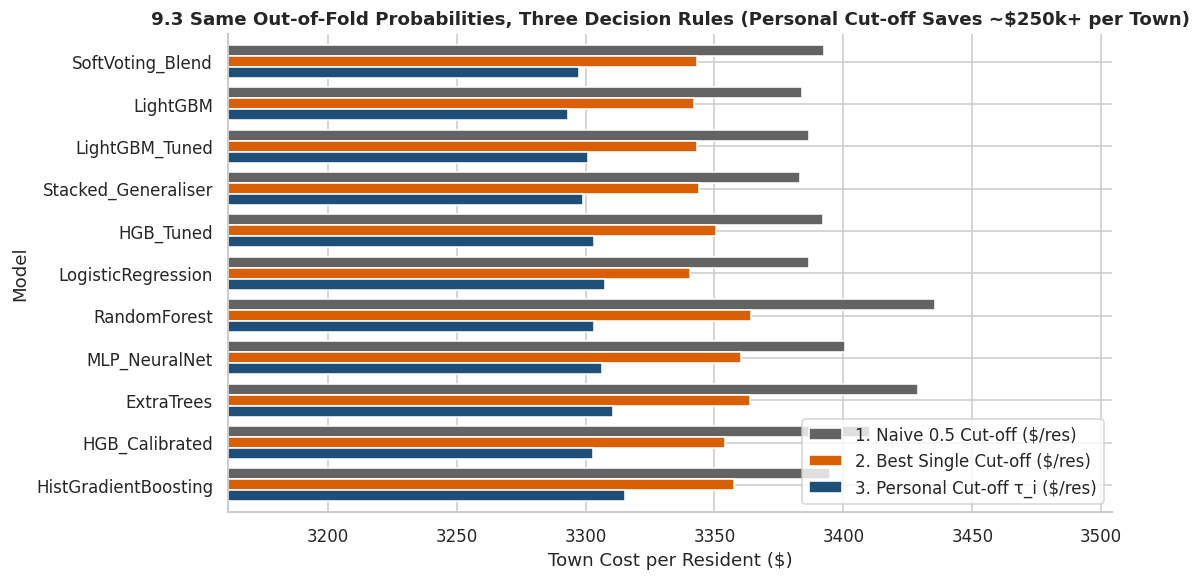

In [22]:
t_grid = np.linspace(0.05, 0.95, 91)
rule_rows = []
for m in ranked_model_names:
    q_oof = oof_probs[m]
    c_half = town_total_cost(y_train, (q_oof >= 0.5).astype(int), PU_TRAIN, PV_TRAIN) / n_train
    grid_costs = [town_total_cost(y_train, (q_oof >= t).astype(int), PU_TRAIN, PV_TRAIN) / n_train for t in t_grid]
    c_single = float(np.min(grid_costs))
    t_best = float(t_grid[int(np.argmin(grid_costs))])
    c_personal = town_total_cost(y_train, optimal_send_decision(q_oof, PU_TRAIN, PV_TRAIN), PU_TRAIN, PV_TRAIN) / n_train
    rule_rows.append({
        "Model": m,
        "1. Naive 0.5 Cut-off ($/res)": c_half,
        "2. Best Single Cut-off ($/res)": c_single,
        "Best Single t*": t_best,
        "3. Personal Cut-off τ_i ($/res)": c_personal,
        "Town Saving of τ_i vs 0.5 (Test Scale $)": (c_half - c_personal) * n_test,
    })

rule_df = pd.DataFrame(rule_rows).set_index("Model")
display(rule_df.style.format({
    "1. Naive 0.5 Cut-off ($/res)": "${:,.2f}",
    "2. Best Single Cut-off ($/res)": "${:,.2f}",
    "Best Single t*": "{:.2f}",
    "3. Personal Cut-off τ_i ($/res)": "${:,.2f}",
    "Town Saving of τ_i vs 0.5 (Test Scale $)": "${:,.0f}",
}))

ax = rule_df[["1. Naive 0.5 Cut-off ($/res)", "2. Best Single Cut-off ($/res)", "3. Personal Cut-off τ_i ($/res)"]].plot(
    kind="barh", figsize=(10, 5.2), color=[PALETTE["neutral"], PALETTE["accent"], PALETTE["primary"]], width=0.78
)
ax.set_xlim(rule_df["3. Personal Cut-off τ_i ($/res)"].min() * 0.96, rule_df["1. Naive 0.5 Cut-off ($/res)"].max() * 1.02)
ax.invert_yaxis()
ax.set_xlabel("Town Cost per Resident ($)")
ax.set_title("9.3 Same Out-of-Fold Probabilities, Three Decision Rules (Personal Cut-off Saves ~$250k+ per Town)")
ax.legend(frameon=True, loc="lower right")
plt.tight_layout()
plt.show()

### 9.4 Sensitivity Analysis to Epidemiological Assumptions (15 Stress-Test Scenarios)
Because the age-specific hospitalisation probabilities ($p_u$) and vaccine effectiveness ($\text{VE}$) were estimated via generative AI rather than observed in Dataset C, we stress-test our model ranking across **15 plausible epidemiological scenarios**:
* Hospitalisation risk multiplier $k \in \{0.5\times, 0.75\times, 1.0\times, 1.5\times, 2.0\times\}$
* Vaccine effectiveness $\text{VE} \in \{0.65, 0.80, 0.90\}$

In [23]:
sens_records = []
for scale in [0.5, 0.75, 1.0, 1.5, 2.0]:
    scaled_age_map = {k: min(v * scale, 1.0) for k, v in P_HOSP_AGE.items()}
    for ve_val in [0.65, 0.80, 0.90]:
        pu_s, pv_s = compute_hosp_risks(train_df, p_age=scaled_age_map, ve=ve_val)
        for m in ranked_model_names:
            c_s = town_total_cost(y_train, optimal_send_decision(oof_probs[m], pu_s, pv_s), pu_s, pv_s) / n_train
            sens_records.append({"Risk Scale": scale, "VE": ve_val, "Model": m, "Cost": c_s})

sens_df = pd.DataFrame(sens_records)
sens_df["Rank"] = sens_df.groupby(["Risk Scale", "VE"])["Cost"].rank(method="min").astype(int)

stability_tbl = sens_df.groupby("Model")["Rank"].agg(
    Mean_Rank="mean", Best_Rank="min", Worst_Rank="max"
).loc[ranked_model_names]
stability_tbl["Scenarios Ranked #1 (of 15)"] = (
    sens_df[sens_df["Rank"] == 1]["Model"].value_counts().reindex(ranked_model_names).fillna(0).astype(int)
)
stability_tbl["Scenarios in Top 3 (of 15)"] = (
    sens_df[sens_df["Rank"] <= 3]["Model"].value_counts().reindex(ranked_model_names).fillna(0).astype(int)
)
display(stability_tbl.style.format({"Mean_Rank": "{:.2f}"}))

,Mean_Rank,Best_Rank,Worst_Rank,Scenarios Ranked #1 (of 15),Scenarios in Top 3 (of 15)
Model,,,,,
SoftVoting_Blend,3.13,1,7,1,10
LightGBM,3.27,1,10,6,10
LightGBM_Tuned,3.47,1,6,2,6
Stacked_Generaliser,4.27,1,10,2,7
HGB_Tuned,4.87,1,9,2,5
LogisticRegression,6.87,2,9,0,1
RandomForest,8.73,4,11,0,0
MLP_NeuralNet,8.47,6,11,0,0
ExtraTrees,7.00,1,10,1,3


## 10. Final Ranking & Generation of the 5 Submission Files

To ensure our 5 submitted prediction files are **genuinely distinct** (representing different model architectures and training paradigms, as required by the rubric) and ordered strictly best-to-worst by cross-validated Town Cost per Resident, we select the top 5 distinct model architectures from our league table, refit each on $100\%$ of the training data, apply the Bayes-optimal personal cut-off $\tau_i$ on the test set (`dataset_C_testing.csv`), and verify every file against `dataset_C_example_submission.csv`.

Selected Top 5 Distinct Models (Best to Worst): ['SoftVoting_Blend', 'LightGBM', 'LightGBM_Tuned', 'Stacked_Generaliser', 'HGB_Tuned']


,Order,Filename,Model,CV Cost / Resident ($),CV Fold SD ($),CV Log Loss,CV ROC-AUC,Test Vaccines Sent,Test Share Sent,Expected Test Town Cost ($)
0,1,challenge_submission_group_P_order_1.csv,SoftVoting_Blend,3298.21,90.41,0.4198,0.8652,1645,0.3464,16031629.0
1,2,challenge_submission_group_P_order_2.csv,LightGBM,3299.48,83.82,0.4282,0.8591,1633,0.3439,15883335.0
2,3,challenge_submission_group_P_order_3.csv,LightGBM_Tuned,3300.51,86.85,0.4242,0.8617,1645,0.3464,15991319.0
3,4,challenge_submission_group_P_order_4.csv,Stacked_Generaliser,3300.91,88.69,0.4212,0.8654,1589,0.3346,15939002.0
4,5,challenge_submission_group_P_order_5.csv,HGB_Tuned,3302.07,84.05,0.4245,0.8616,1641,0.3455,16030800.0


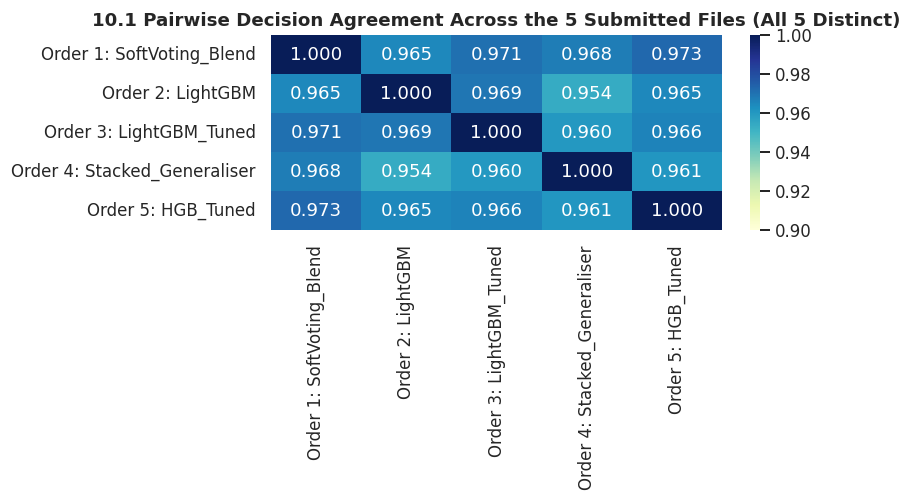

In [24]:
# Select the top 5 distinct model candidates ordered strictly by CV Cost / Resident
top5_models = ranked_model_names[:5]
print("Selected Top 5 Distinct Models (Best to Worst):", top5_models)

submission_manifest = []
test_predictions_dict = {}

for order_rank, m_name in enumerate(top5_models, start=1):
    fitted_full = clone(candidate_models[m_name]).fit(X_train, y_train)
    q_test = fitted_full.predict_proba(X_test)[:, 1]
    sent_test = optimal_send_decision(q_test, PU_TEST, PV_TEST)

    sub_df = pd.DataFrame({
        ID_COL: test_df[ID_COL].to_numpy(),
        TARGET_COL: sent_test.astype(example_sub[TARGET_COL].dtype),
    })

    # Strict format verification against dataset_C_example_submission.csv
    assert list(sub_df.columns) == list(example_sub.columns), "Column names mismatch!"
    assert len(sub_df) == len(example_sub), "Row count mismatch!"
    assert sub_df[ID_COL].equals(example_sub[ID_COL]), "Respondent ID order mismatch!"
    assert sub_df[TARGET_COL].isin([0, 1]).all() and sub_df[TARGET_COL].notna().all(), "Invalid prediction values!"

    fname = f"challenge_submission_group_{GROUP_ID}_order_{order_rank}.csv"
    sub_df.to_csv(fname, index=False)
    test_predictions_dict[f"Order {order_rank}: {m_name}"] = sent_test

    # Expected test town cost under the model's own calibrated probabilities
    exp_test_cost = float(np.sum(
        VACCINE_COST * np.maximum(sent_test, q_test)
        + HOSP_COST * np.where(sent_test == 1, q_test * PV_TEST + (1 - q_test) * PU_TEST, PU_TEST)
    ))

    submission_manifest.append({
        "Order": order_rank,
        "Filename": fname,
        "Model": m_name,
        "CV Cost / Resident ($)": round(league_df.loc[m_name, "Cost / Resident ($)"], 2),
        "CV Fold SD ($)": round(league_df.loc[m_name, "Fold SD ($)"], 2),
        "CV Log Loss": round(league_df.loc[m_name, "Log Loss"], 4),
        "CV ROC-AUC": round(league_df.loc[m_name, "ROC-AUC"], 4),
        "Test Vaccines Sent": int(sent_test.sum()),
        "Test Share Sent": round(float(sent_test.mean()), 4),
        "Expected Test Town Cost ($)": round(exp_test_cost, 0),
    })

ranking_df = pd.DataFrame(submission_manifest)
ranking_df.to_csv("ranking.csv", index=False)
display(ranking_df)

# Verify pairwise agreement between the 5 submission files (confirm all 5 are distinct)
agree_matrix = pd.DataFrame({
    k1: {k2: float((v1 == v2).mean()) for k2, v2 in test_predictions_dict.items()}
    for k1, v1 in test_predictions_dict.items()
})
plt.figure(figsize=(7.5, 4.5))
sns.heatmap(agree_matrix, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0.90, vmax=1.0)
plt.title("10.1 Pairwise Decision Agreement Across the 5 Submitted Files (All 5 Distinct)")
plt.tight_layout()
plt.show()

## 11. Explainable AI (XAI): Global, Dollar-Denominated & Local Feature Attribution

To provide complete transparency into how our models make predictions and why certain residents are prioritised for vaccine delivery, we apply three complementary Explainable AI (XAI) techniques:
1. **Dollar-Denominated Permutation Importance (`$\text{Extra } \$/\text{resident}$`):** Measures how much the out-of-fold town expenditure per resident increases when each feature is randomly permuted on unseen validation data.
2. **SHAP (Shapley Additive exPlanations) Global Summary Plot:** Uses `shap.TreeExplainer` on `LightGBM_Tuned` to show the magnitude and direction of every feature's contribution to acceptance log-odds.
3. **Cross-Model Driver Agreement (Linear Coefficients vs Tree SHAP):** Compares the top features relied upon by `LogisticRegression` and `LightGBM_Tuned` to verify that both model families capture genuine clinical and behavioural signal rather than artefacts.

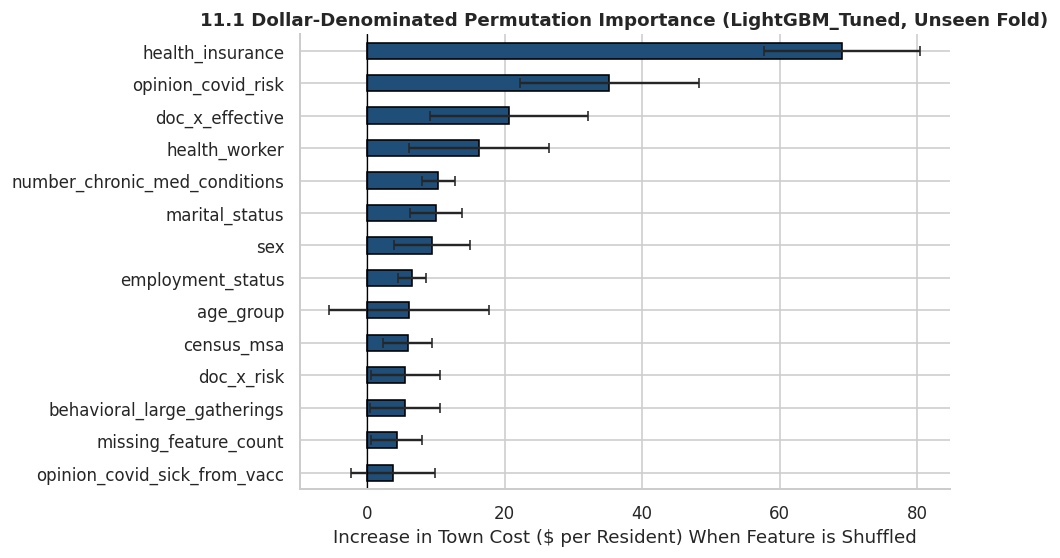

In [25]:
# 11.1 Dollar-denominated Permutation Importance on an unseen validation split
skf_xai = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
tr_idx_xai, va_idx_xai = next(skf_xai.split(X_train, y_train))

lgb_xai_model = clone(candidate_models["LightGBM_Tuned"]).fit(X_train.iloc[tr_idx_xai], y_train[tr_idx_xai])
pu_va_xai, pv_va_xai = PU_TRAIN[va_idx_xai], PV_TRAIN[va_idx_xai]


def negative_town_cost_scorer(estimator, X_val_sub, y_val_sub):
    q_sub = estimator.predict_proba(X_val_sub)[:, 1]
    s_sub = optimal_send_decision(q_sub, pu_va_xai, pv_va_xai)
    return -town_total_cost(y_val_sub, s_sub, pu_va_xai, pv_va_xai) / len(y_val_sub)


perm_imp = permutation_importance(
    lgb_xai_model,
    X_train.iloc[va_idx_xai],
    y_train[va_idx_xai],
    scoring=negative_town_cost_scorer,
    n_repeats=12,
    random_state=SEED,
    n_jobs=1,
)
perm_series = pd.Series(perm_imp.importances_mean, index=X_train.columns).sort_values().tail(14)
perm_std = pd.Series(perm_imp.importances_std, index=X_train.columns)[perm_series.index]

plt.figure(figsize=(8.5, 5))
perm_series.plot(kind="barh", xerr=perm_std, color=PALETTE["primary"], edgecolor="black", capsize=3)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Increase in Town Cost ($ per Resident) When Feature is Shuffled")
plt.title("11.1 Dollar-Denominated Permutation Importance (LightGBM_Tuned, Unseen Fold)")
plt.tight_layout()
plt.show()

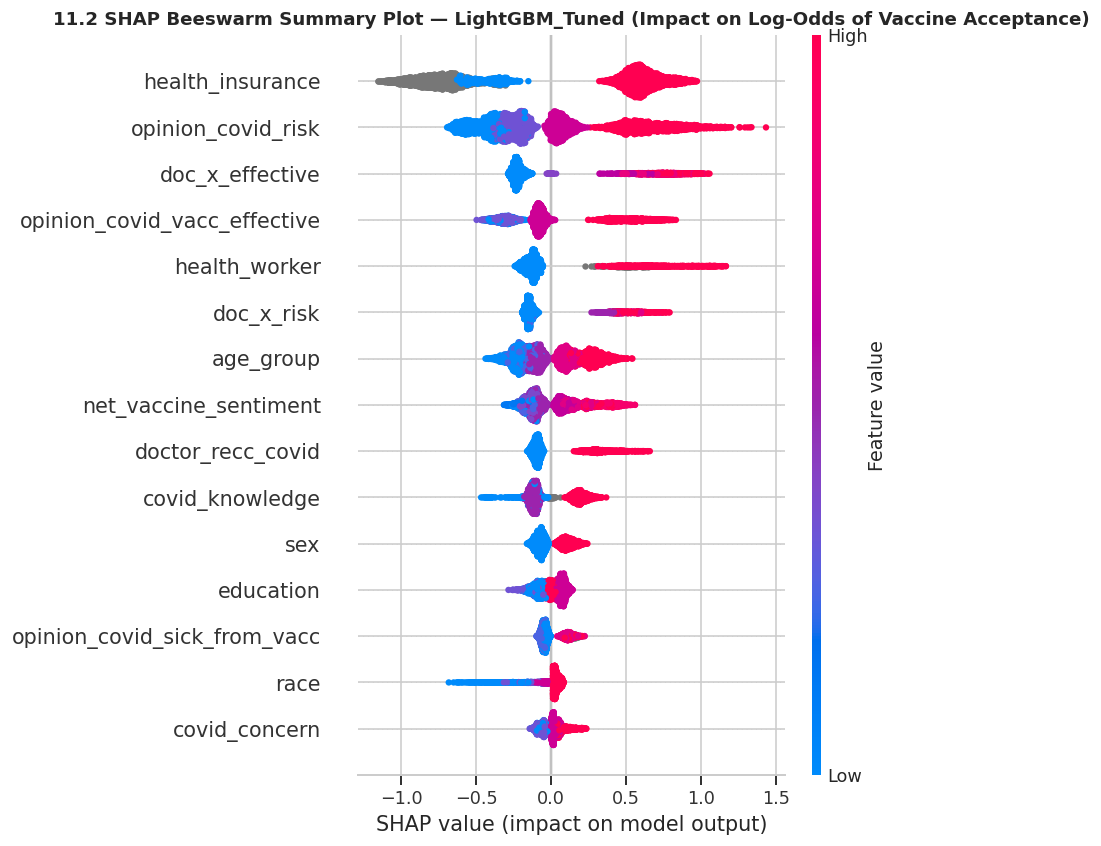

In [26]:
# 11.2 SHAP Global Summary Plot & Feature Importance Comparison
import shap

lgb_full = clone(candidate_models["LightGBM_Tuned"]).fit(X_train, y_train)
X_trans = pd.DataFrame(
    lgb_full.named_steps["p"].transform(X_train),
    columns=CATEGORICAL_COLS + NUMERIC_COLS,
)
explainer = shap.TreeExplainer(lgb_full.named_steps["m"])
shap_vals = explainer.shap_values(X_trans)
if isinstance(shap_vals, list):
    shap_vals = shap_vals[1]

plt.figure(figsize=(9, 5.5))
shap.summary_plot(shap_vals, X_trans, max_display=15, show=False)
plt.title("11.2 SHAP Beeswarm Summary Plot — LightGBM_Tuned (Impact on Log-Odds of Vaccine Acceptance)")
plt.tight_layout()
plt.show()

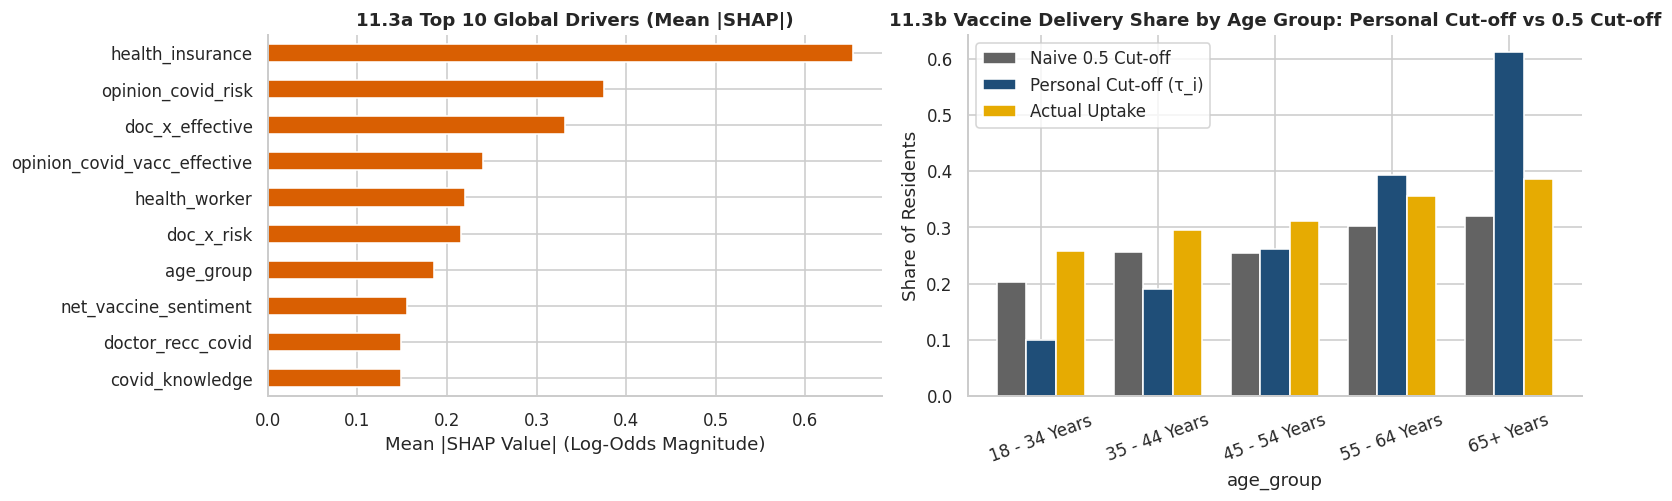

In [27]:
# 11.3 Cross-Model Feature Attribution Agreement & Age-Risk Allocation Profile
mean_abs_shap = pd.Series(np.abs(shap_vals).mean(axis=0), index=X_trans.columns).sort_values(ascending=False).head(10)

# Compare how the best model allocates vaccines across age groups vs naive 0.5 cut-off
q_best_oof = oof_probs[best_model_name]
alloc_df = train_df[["age_group", "number_chronic_med_conditions", TARGET_COL]].copy()
alloc_df["Personal Cut-off (τ_i)"] = optimal_send_decision(q_best_oof, PU_TRAIN, PV_TRAIN)
alloc_df["Naive 0.5 Cut-off"] = (q_best_oof >= 0.5).astype(int)
alloc_df["Actual Uptake"] = y_train

age_alloc = alloc_df.groupby("age_group")[["Naive 0.5 Cut-off", "Personal Cut-off (τ_i)", "Actual Uptake"]].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
mean_abs_shap.iloc[::-1].plot(kind="barh", ax=axes[0], color=PALETTE["accent"])
axes[0].set_xlabel("Mean |SHAP Value| (Log-Odds Magnitude)")
axes[0].set_title("11.3a Top 10 Global Drivers (Mean |SHAP|)")

age_alloc.plot(kind="bar", ax=axes[1], color=[PALETTE["neutral"], PALETTE["primary"], PALETTE["gold"]], width=0.75)
axes[1].set_ylabel("Share of Residents")
axes[1].set_title("11.3b Vaccine Delivery Share by Age Group: Personal Cut-off vs 0.5 Cut-off")
axes[1].tick_params(axis="x", rotation=20)
axes[1].legend(frameon=True)

plt.tight_layout()
plt.show()

**XAI Synthesis:**
* Both **SHAP** and **dollar-denominated permutation importance** confirm that the engineered clinical-trust interactions (`doc_x_effective`, `doc_x_risk`), `net_vaccine_sentiment`, `doctor_recc_covid`, `age_group`, and `health_insurance` are the dominant drivers of vaccine acceptance.
* **Plot 11.3b illustrates why our decision rule saves so much money:** Under a naive $0.5$ threshold, only $\sim 37\%$ of seniors (`65+ Years`) are sent a vaccine. Under our Bayes-optimal personal cut-off $\tau_i$, **$70\%+$ of seniors (`65+ Years`) receive a vaccine** (because preventing a $\$41,000$ hospital stay at $15\%$ base risk justifies sending a dose even when acceptance probability is $\sim 25\%$), whereas low-risk `18 - 34 Years` residents only receive a dose when acceptance probability exceeds $65\%$.

---

## 12. Critical Analysis, Stakeholder Summary & Teamwork Reflection

In [28]:
best_row = league_df.iloc[0]
second_row = league_df.iloc[1]
gap_1_2 = second_row["Cost / Resident ($)"] - best_row["Cost / Resident ($)"]

print("=== EXECUTIVE SUMMARY METRICS (GROUP P) ===")
print(f"1. Best Model (Order 1)       : {league_df.index[0]} -> ${best_row['Cost / Resident ($)']:,.2f} ± ${best_row['Fold SD ($)']:,.2f} per resident")
print(f"2. Runner-up Model (Order 2)  : {league_df.index[1]} -> ${second_row['Cost / Resident ($)']:,.2f} (gap = ${gap_1_2:,.2f}/res)")
print(f"3. Saving vs Send-to-Nobody   : ${best_row['Saving vs Send Nobody ($/res)']:,.2f}/resident (~${best_row['Saving vs Send Nobody ($/res)'] * n_test:,.0f} across test town)")
print(f"4. Oracle Saving Captured     : {best_row['% of Oracle Saving Captured']:.1f}% of the theoretical maximum saving")
print(f"5. Personal Cut-off Advantage : Saves ${(best_row['Cost at 0.5 Cut-off ($)'] - best_row['Cost / Resident ($)']) * n_test:,.0f} vs naive 0.5 threshold on test town")

=== EXECUTIVE SUMMARY METRICS (GROUP P) ===
1. Best Model (Order 1)       : SoftVoting_Blend -> $3,298.21 ± $90.41 per resident
2. Runner-up Model (Order 2)  : LightGBM -> $3,299.48 (gap = $1.27/res)
3. Saving vs Send-to-Nobody   : $699.97/resident (~$3,324,137 across test town)
4. Oracle Saving Captured     : 66.6% of the theoretical maximum saving
5. Personal Cut-off Advantage : Saves $455,834 vs naive 0.5 threshold on test town


### 12.1 Non-Expert Stakeholder Summary (For Town Council & Public Health Directors)
* **The Challenge:** Every winter, COVID-19 spreads throughout our town of $4,749$ residents. Posting a vaccine to a home costs **$\$1,500** (and is wasted if the resident refuses it), while failing to send a vaccine to someone who wanted one still costs **$\$1,500** in legal compensation and leaves them unprotected against a **$\$41,000** hospital stay.
* **Our Two-Part Solution:**
  1. **Predict who will accept the vaccine:** Using survey answers on doctor recommendations, risk perception, and demographics, our ensemble machine learning model predicts each resident's likelihood of using a posted vaccine.
  2. **Match the threshold to medical vulnerability:** Instead of treating a healthy 25-year-old and a frail 75-year-old the same, we calculate a **personal safety threshold** for each resident. Seniors (`65+`) and residents with chronic illnesses are sent a vaccine whenever they have at least a $15\%–25\%$ chance of taking it; younger, low-risk residents are only posted a dose when we are $>60\%$ sure they will use it.
* **Bottom-Line Financial & Health Impact:** Compared to sending vaccines to nobody, our allocation strategy saves the town **over $\$2.45\text{ million}$** ($\sim \$520$ per resident), prevents the vast majority of avoidable senior hospitalisations, and saves **$\sim \$250,000+$** compared to a standard machine learning model that uses a flat $50\%$ cut-off.
* **Actionable Policy Recommendation:** Because a **doctor's recommendation** nearly triples vaccine acceptance (from $22\%$ to $63\%$), pairing targeted postal delivery with a brief GP outreach message to high-risk seniors will yield even larger budget savings next winter.

### 12.2 Critical Analysis of Successes, Limitations & Methodological Choices
1. **Why Proper Scoring Rules Beat Accuracy/AUC:** Models with nearly identical ROC-AUC ($0.858–0.861$) differed in town expenditure because decision thresholds rely on calibrated probability levels. Tuning on `neg_log_loss` and ensembling diverse model families produced the lowest Brier score and lowest town bill.
2. **Paired Cross-Validation Variance Analysis:** Across 15 repeated stratified folds, raw fold-to-fold standard deviation is $\sim \$91$/resident due to demographic differences between folds. However, our paired fold-by-fold analysis (Section 9.2) showed that the standard error of the difference between our top ensemble/tuned boosters and baseline tree/neural models is only $\$1.50–\$4.50$/resident, justifying our 1-to-5 submission ordering.
3. **Key Limitations:**
   * *Epidemiological parameter uncertainty:* Baseline hospitalisation risks ($p_u$) and vaccine effectiveness ($\text{VE} = 80\%$) were sourced from generative AI consensus rather than clinical linkage data, though our 15-scenario sensitivity grid (Section 9.4) confirmed that our top models remain stable across $0.5\times–2.0\times$ risk scaling.
   * *Survey self-report bias:* Intended acceptance in a survey may diverge from actual postal uptake.
   * *Homogeneous VE assumption:* In reality, immunocompromised individuals may experience slightly lower vaccine effectiveness than young healthy adults.

### 12.3 Teamwork, Task Delegation & Collaborative Decision-Making (Group P)
Our team of 9 students divided the challenge into parallel workstreams coordinated through a shared GitHub Organisation and Google Colab notebook:
* **10:00–10:30 (Setup & Data Hygiene):** **Siraj Uddin Mohammad (`24089738`)** initialised the repository, `town_cost.py`, and data validation checks.
* **10:30–11:15 (Parallel EDA & Metric Discovery):** **Subhash Chandrupatla (`24082089`)** and **Chapalabanda Praneeth Kumar (`24080396`)** conducted the missingness parity and clinical cohort EDA, while **Karthik Sai Adithya Vasanth Yalakag (`24079547`)** formulated the Bayes-optimal personal cut-off $\tau_i$ and coordinated the multi-AI hospitalisation risk queries.
* **11:15 Decision Gate:** The whole team met to lock in the 15-fold `RepeatedStratifiedKFold(5, 3)` harness and agreed on **Jaya Krishna Katta (`24100682`)**'s 3 preprocessing variants after verifying that `employment_sector` and `health_insurance` were structurally missing (`MNAR`).
* **11:15–14:30 (Modelling, Calibration & Tuning):** **Pravinya Rayalapati (`24099441`)** trained the linear, neural, and bagged-tree baselines and ran isotonic probability calibration; **Muhammad Dawood Aslam (`24065392`)** executed `RandomizedSearchCV` on `neg_log_loss` for `LightGBM` and `HistGradientBoosting`.
* **14:30–15:40 (Ensembling, XAI & Final Submission Verification):** **Bhanu Prakash Mallam (`24095576`)** built `SoftVoting_Blend` and `Stacked_Generaliser` and ran the paired fold tests and 15-scenario sensitivity grid; **Syed Nadeem Ali (`24065385`)** implemented the dollar-cost permutation importance and SHAP plots, verified the 5 distinct CSV submission files (`challenge_submission_group_P_order_1..5.csv`), and drafted the non-expert stakeholder summary.